# Complaint Intelligence for Retail Banks

**MCSBT · Introduction to AI and Machine Learning · Final Term Project**

Group: Yohannes Belay Woldeyes, Vidak Vukadinovic, Jorge Plaza de los Reyes Álvarez

**The problem in plain words.** When a US customer is unhappy with their bank, they can file a written complaint with the government's consumer watchdog, the CFPB, and the bank has 15 days to respond. A large bank receives thousands of these a year, and people read them one by one. Serious complaints wait in the same queue as small ones, and when something breaks for many customers at once, the pattern is noticed late.

**What we built.** A tool that reads every complaint as it arrives, sends it to the right team, flags the ones likely to end in money paid back, warns managers when one kind of problem suddenly grows, and explains each warning from the complaints themselves.

| Stage | Question it answers | Course method |
|---|---|---|
| Clean | Which complaints are copy-paste campaigns? | Deduplication (Assignment 1),<br>sentence embeddings + FAISS (Session 7) |
| Route | Which team should handle this complaint? | **Word2Vec** (Session 5, Assignment 2, Midterm),<br>compared with an LLM (Session 6) |
| Prioritise | Which complaints will end in a payout? | Supervised prediction (Session 3) |
| Watch | Which problems are surging this week? | **LDA topic modeling** (Sessions 3 and 5) |
| Explain | Why is this problem surging? | **RAG** with an agent and filters, Qwen3-4B<br>(Sessions 6–8, Assignment 3), prompt tests (Assignment 4) |
| Prove it | Does each part work? | Held-out labels, dated real events, RAGAs,<br>LLM-as-judge with a human spot-check (Session 11) |

The three main AI methods are **Word2Vec**, **LDA topic modeling** and **RAG with an LLM**, and each one feeds the next: Word2Vec handles every single complaint, LDA watches the weekly mix, and RAG explains each alarm LDA raises. Every stage is checked against data we did not create ourselves: the product and issue the consumer chose, how the company actually closed the complaint, and real events with a date.

## 1. Business case

**The problem.** Every complaint a bank receives through the CFPB has to be read, sent to the right product team and answered: the CFPB expects a response within 15 days and a final answer within 60. Today this is done by hand. Problems that hit many customers at once (an outage, a fee error, a scam wave) first show up as a sudden wave of complaints, and a team reading them one by one notices late.

**Background: what the complaint waves of early 2025 were about.** Each of these shows up in our data (sections 4 and 7):

| Date | What happened | Money involved |
|---|---|---|
| Nov 2024 | The CFPB orders Navy Federal Credit Union to refund<br>surprise overdraft fees | More than USD 95 million<br>(the order was ended in July 2025) |
| Dec 2024 | The CFPB sues Zelle's operator and three large banks<br>over how they handled scams | USD 870 million in customer losses claimed<br>(the case was dropped in March 2025) |
| 14 Jan 2025 | The CFPB sues Capital One: its 360 Savings account stayed<br>at 0.30% while a near-identical account paid up to 4.35% | More than USD 2 billion in lost interest claimed;<br>a related class action settled for USD 425 million |
| 15–19 Jan 2025 | A power failure at the vendor FIS delays Capital One<br>direct deposits and payments for several days | Capital One refunded late fees that customers<br>paid elsewhere because of the delay |
| 16 Jan 2025 | The CFPB orders Block (Cash App) to fix its fraud handling<br>and customer service | Up to USD 175 million<br>in refunds and penalties |

Sources: CFPB press releases and enforcement pages; NBC News; American Banker; ConsumerAffairs.

Complaint waves sit next to problems worth hundreds of millions of dollars, and they arrive with the evidence (who, what, since when) in the customers' own words. A bank that reads its complaints as a whole, every week, finds its problems earlier.

**Business model.**

| | |
|---|---|
| Product | Complaint Intelligence: a service that reads every complaint, routes it,<br>scores its payout risk, and sends a weekly surge watch with evidence briefs |
| Customers | US banks and credit unions that receive CFPB complaints, starting with<br>mid-size banks that have no complaint analytics team of their own |
| What they pay for | A yearly subscription priced by complaint volume, plus a fee for adding<br>the bank's own channels (emails, web chats, call-centre notes) |
| Our costs | A small Word2Vec model (runs on a normal CPU), one GPU for the open<br>Qwen3-4B model, and analysts who review new alarms |
| Value for the customer | Hours of manual triage saved, payouts handled first, and problems<br>spotted in days instead of weeks |
| Why us | Trained on public CFPB data, so it works for a new bank on day one; the<br>market-wide view shows a bank when a problem is surging at its peers |

**The AI Canvas** (Session 2, slide 10):

| Box | Our answer |
|---|---|
| Prediction | The right team for each complaint, the chance it ends in a payout,<br>its topic, and an explanation for each topic surge |
| Judgment | Missing a payout case or a surge costs more than reading one<br>extra complaint, so we favour catching cases (recall) |
| Action | Route automatically, review high-risk complaints first, alert managers<br>when a topic surges, and answer their questions from the complaints |
| Outcome | Routing accuracy, payouts caught in the riskiest 20%, surges detected,<br>briefs that are faithful and name the right cause |
| Input | Complaint text, product, issue, company, date |
| Training | 2025 CFPB complaints with their real product, issue and outcome |
| Feedback | Agents correct routes; managers mark alarms as real or not; each<br>month's closed complaints are added to the training data |

**Success targets.** The targets for Clean, Route, Prioritise, Watch and Fairness were fixed before the first run. The Explain stage replaces our first RAG assistant (section 8 says why), and its targets were fixed before it was run.

| Stage | Metric | Compared with | Target |
|---|---|---|---|
| Clean | Flagged copy pairs a person confirms (20-pair check) | – | at least 18 of 20 |
| Route | Accuracy on held-out complaints | Keyword rules | at least 80%,<br>and better than keyword rules |
| Prioritise | Payouts caught when reviewing the riskiest 20% | Random review (20%) | at least 40% (2× random) |
| Watch | Topic coherence (c_v) | Untuned LDA | at least 0.40,<br>and better than untuned |
| Watch | Surge alarm after the dated January 2025 events | – | an alarm within 7 days |
| Explain | Past cases with the same issue in the top 5 (precision@5) | Keyword search (BM25) | better than BM25 |
| Explain | Agent test suite: questions turned into the right filters | First prompt (v1) | at least 90% of checks,<br>and better than v1 |
| Explain | Surge briefs that name the company behind the surge | The same briefs<br>without filters | at least 80%,<br>and better than without |
| Explain | The three January events named in that week's briefs | – | 3 of 3 |
| Explain | RAGAs faithfulness of the briefs | – | at least 0.80 |
| Fairness | Shortfall in payouts caught for Older American<br>and Servicemember complaints | Complaints without a tag | at most 5 percentage points |

## 2. Setup

The notebook is built for a Colab GPU runtime (T4). The OpenAI key is read from Colab Secrets (`OPENAI_API_KEY`), as in Assignments 3 and 4, and is only used for the LLM comparison, topic names and the evaluation judge (`gpt-4o-mini`, list price USD 0.15 per million input tokens and USD 0.60 per million output tokens).

Three switches control the run:

- `QUICK_RUN = True` uses 6,000 complaints for a fast test of the whole notebook.
- `RUN_OPENAI = False` skips every OpenAI call.
- `RUN_QWEN` is switched on automatically when a GPU is available. Qwen3-4B, the open model behind the Explain assistant (section 8), needs it.

Every chart is also saved as a PNG in `figures/` for the slides.

In [1]:
!pip install -q gensim sentence-transformers faiss-cpu rank-bm25
!pip install -q ragas==0.4.3 langchain-community==0.4.1 "huggingface-hub<2"

In [2]:
import os
import re
import json
import time
import random
import shutil
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, classification_report,
                             average_precision_score, roc_auc_score, normalized_mutual_info_score)

from gensim.models import Word2Vec, LdaModel, CoherenceModel
from gensim.models.phrases import Phrases
from gensim.corpora import Dictionary

import torch
import faiss
from sentence_transformers import SentenceTransformer, CrossEncoder
from rank_bm25 import BM25Okapi

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 220)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

QUICK_RUN = False
RUN_OPENAI = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RUN_QWEN = DEVICE == "cuda"

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
print(f"Device: {DEVICE} | QUICK_RUN={QUICK_RUN} | RUN_OPENAI={RUN_OPENAI} | RUN_QWEN={RUN_QWEN}")

Device: cuda | QUICK_RUN=False | RUN_OPENAI=True | RUN_QWEN=True


In [3]:
JUDGE_MODEL = "gpt-4o-mini"
PRICE_PER_1M_TOKENS = {"input": 0.15, "output": 0.60}

client = None
if RUN_OPENAI:
    from openai import OpenAI
    try:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    except Exception:
        if not os.environ.get("OPENAI_API_KEY"):
            from getpass import getpass
            os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")
    client = OpenAI()


def ask_openai(system, user, max_tokens=300, json_mode=False):
    extra = {"response_format": {"type": "json_object"}} if json_mode else {}
    for attempt in range(3):
        try:
            response = client.chat.completions.create(
                model=JUDGE_MODEL, temperature=0, max_completion_tokens=max_tokens,
                messages=[{"role": "system", "content": system}, {"role": "user", "content": user}], **extra)
            usage = response.usage
            return response.choices[0].message.content.strip(), usage.prompt_tokens, usage.completion_tokens
        except Exception as error:
            if attempt == 2:
                raise error
            time.sleep(5)


print("OpenAI model:", JUDGE_MODEL if client else "switched off")

OpenAI model: gpt-4o-mini


In [4]:
PRODUCTS = ["Checking or savings account", "Credit card", "Money transfer, virtual currency, or money service",
            "Mortgage", "Vehicle loan or lease"]
SHORT = dict(zip(PRODUCTS, ["Checking/savings", "Credit card", "Money transfer", "Mortgage", "Vehicle loan"]))
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
PRODUCT_COLOR = dict(zip(PRODUCTS, SERIES))
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 11, "text.color": INK, "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.titlepad": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "lines.linewidth": 2,
})


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()

## 3. Data: source and procurement

| | |
|---|---|
| Source | CFPB Consumer Complaint Database, official narratives archive<br>(US government open data, listed on Data.gov) |
| Link | [consumerfinance.gov narratives archive](https://www.consumerfinance.gov/foia-requests/foia-electronic-reading-room/cfpb-consumer-complaint-database-narratives-archive/) |
| Files | The six 2025 exports, January–February to November–December:<br>5.4 million complaints, 1.2 million with a written story |
| Privacy | The CFPB removes names, account numbers and dates before<br>publishing; they appear as XXXX |
| Why 2025 | The CFPB's product and issue categories did not change between<br>August 2023 and October 2026, so every label means the same thing |
| Scope | The five product lines a retail bank runs: checking/savings,<br>credit cards, money transfers, mortgages, vehicle loans |
| Size | 183,544 complaints in scope; a random sample of 60,000<br>(seed 42) keeps Colab fast |
| Build script | `prepare_dataset.py` reads the six zip files and writes<br>`cfpb_bank_complaints_2025.csv` |

| Column | Meaning |
|---|---|
| `complaint_id` | CFPB complaint number (can be looked up on consumerfinance.gov) |
| `date_received` | Date the CFPB received the complaint |
| `product`, `sub_product` | Product chosen by the consumer |
| `issue`, `sub_issue` | Problem chosen by the consumer |
| `narrative` | The consumer's own description |
| `company`, `state` | Company the complaint is about, consumer's state |
| `tags` | "Older American", "Servicemember" or empty |
| `company_response` | How the company closed it, for example "Closed with monetary relief" |
| `timely_response` | Whether the company answered on time |

Upload `cfpb_bank_complaints_2025.zip` to the Colab file panel before running the next cell.

In [5]:
DATA_PATH = "cfpb_bank_complaints_2025.zip"

df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
if QUICK_RUN:
    df = df.sample(6000, random_state=SEED)
df["date_received"] = pd.to_datetime(df["date_received"])
df = df.sort_values(["date_received", "complaint_id"]).reset_index(drop=True)
df["week"] = df["date_received"].dt.to_period("W").dt.start_time
df["payout"] = (df["company_response"] == "Closed with monetary relief").astype(int)
df["n_words"] = df["narrative"].str.split().str.len()
SCALE = len(df) / 60_000

first_day = df["date_received"].min().normalize()
last_day = df["date_received"].max().normalize()
first_monday = first_day + pd.Timedelta(days=(7 - first_day.weekday()) % 7)
last_full_monday = last_day - pd.Timedelta(days=(last_day.weekday() + 1) % 7) - pd.Timedelta(days=6)
WEEKS = pd.date_range(first_monday, last_full_monday, freq="W-MON")

print(f"{len(df):,} complaints about {df['company'].nunique():,} companies, "
      f"received {first_day:%d %b %Y} to {last_day:%d %b %Y} ({len(WEEKS)} full weeks)")
display(df[["complaint_id", "date_received", "product", "issue", "company", "company_response", "narrative"]].head(3))

60,000 complaints about 925 companies, received 01 Jan 2025 to 31 Dec 2025 (51 full weeks)


,complaint_id,date_received,product,issue,company,company_response,narrative
0,11334577,2025-01-01,Mortgage,Trouble during payment process,"CARRINGTON MORTGAGE SERVICES, LLC",Closed with explanation,On XX/XX/year> I called Carrington Mortgage to request removal of escrow payments from our monthly mortgage payment so that my husband and I could pay these ourselves. They told me to send a written request to a spec...
1,11334654,2025-01-01,Checking or savings account,Problem caused by your funds being low,WELLS FARGO & COMPANY,Closed with explanation,Thousands of dollars of overdraft fees. \n\nWells Fargo
2,11334680,2025-01-01,Checking or savings account,Problem caused by your funds being low,KEYCORP,Closed with explanation,"I deposited a check for {$80.00} on XX/XX/year> with Key Bank via their mobile app. The check cleared and was credited to my account. 4 days later, Key Bank hit me with a {$72.00} fee. They claimed that the check was..."


In [6]:
overview = (df.groupby("product")
              .agg(complaints=("complaint_id", "size"),
                   median_words=("n_words", "median"),
                   payout_rate=("payout", "mean"),
                   on_time=("timely_response", lambda s: (s == "Yes").mean()),
                   top_company=("company", lambda s: s.value_counts().index[0]))
              .reindex(PRODUCTS))
overview.insert(1, "share", overview["complaints"] / len(df))
display(overview.style.format({"complaints": "{:,}", "share": "{:.1%}", "median_words": "{:.0f}",
                               "payout_rate": "{:.1%}", "on_time": "{:.1%}"}))

,complaints,share,median_words,payout_rate,on_time,top_company
product,,,,,,
Checking or savings account,"16,768",27.9%,129,10.4%,99.2%,NAVY FEDERAL CREDIT UNION
Credit card,"13,578",22.6%,168,15.7%,99.5%,CAPITAL ONE FINANCIAL CORPORATION
"Money transfer, virtual currency, or money service","21,304",35.5%,102,2.0%,98.9%,"Block, Inc."
Mortgage,"4,537",7.6%,219,1.8%,98.3%,"Shellpoint Partners, LLC"
Vehicle loan or lease,"3,813",6.4%,184,2.5%,98.1%,"SANTANDER HOLDINGS USA, INC."


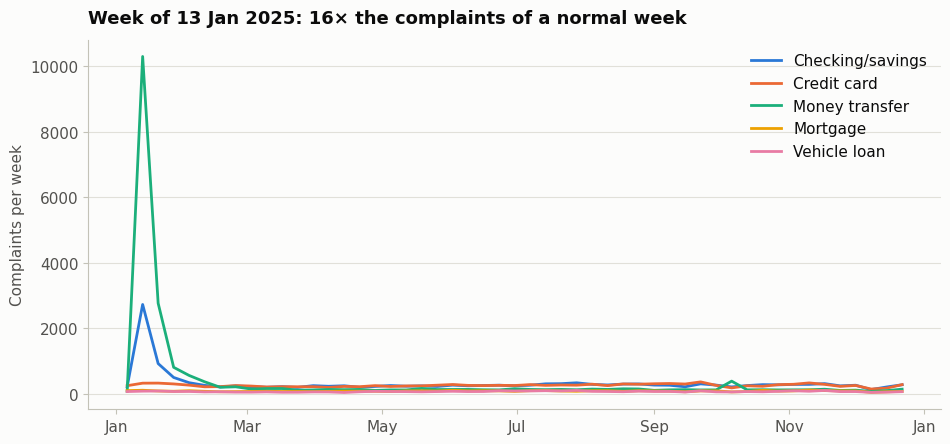

In [7]:
weekly = (df[df["week"].isin(WEEKS)].groupby(["week", "product"]).size()
            .unstack(fill_value=0).reindex(index=WEEKS, columns=PRODUCTS, fill_value=0))
weekly_total = weekly.sum(axis=1)
peak_week = weekly_total.idxmax()
peak_ratio = weekly_total.max() / weekly_total.median()

fig, ax = plt.subplots(figsize=(11, 4.8))
for product in PRODUCTS:
    ax.plot(weekly.index, weekly[product], color=PRODUCT_COLOR[product], label=SHORT[product])
ax.set_title(f"Week of {peak_week:%d %b %Y}: {peak_ratio:.0f}× the complaints of a normal week")
ax.set_ylabel("Complaints per week")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper right")
save_fig(fig, "fig01_weekly_complaints_by_product")

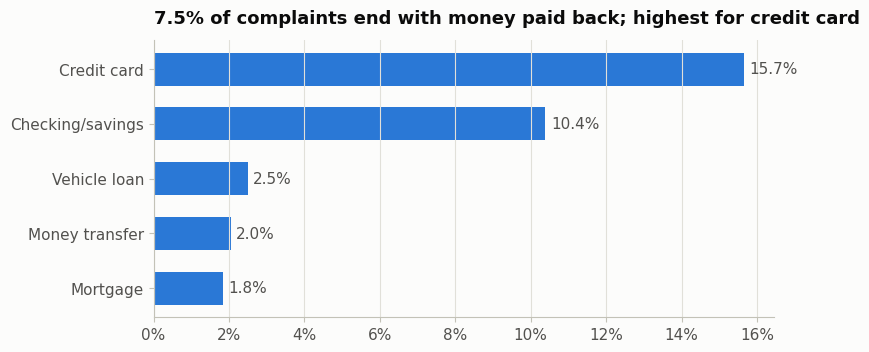

In [8]:
rates = overview["payout_rate"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh([SHORT[p] for p in rates.index], rates.values, color=SERIES[0], height=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in rates.values], padding=4, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title(f"{df['payout'].mean():.1%} of complaints end with money paid back; "
             f"highest for {SHORT[rates.index[-1]].lower()}")
save_fig(fig, "fig02_payout_rate_by_product")

## 4. Clean: copy-paste campaigns

Many complaints are not written from scratch. People share templates online and file the same text, and some people file one complaint against several companies. We need to find these copies for three reasons:

1. **Business:** a campaign can be answered in bulk with one reviewed response.
2. **Honest evaluation:** if one copy lands in the training set and another in the test set, the model has seen the answer and its score looks better than it really is. The low-scoring example project had no such check.
3. **Early warning:** a sudden campaign is itself a signal that something happened.

**Design choices.**

- Exact copies are found after cleaning the text, as in Assignment 1. Cleaning lowercases the text, replaces amounts with the word "amount" and removes apostrophes before other punctuation, so "didn't" stays one word ("didnt") instead of breaking into "didn" and "t".
- Near copies (same template, different names or amounts) are found by meaning *and* by wording. Each complaint is turned into a sentence embedding (`all-mpnet-base-v2`, Session 7, Assignment 3), and FAISS finds its 10 closest complaints.
- A pair counts as a copy only if both checks agree: cosine similarity of at least 0.95, *and* at least half of their three-word sequences are shared.
- The same embeddings are reused later for the RAG assistant, so they are computed once.

In [9]:
def readable(text):
    text = re.sub(r"\{\$([\d,\.]+)\}", r"$\1", text)
    text = re.sub(r"X{2,}(?:/X{2,})*(?:/year>|/\d+)?", " ", text)
    text = re.sub(r"year>", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def clean_text(text):
    text = text.lower()
    text = re.sub(r"\$[\d,\.]+", " amount ", text)
    text = re.sub(r"['\u2019]", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


df["text"] = df["narrative"].map(readable)
df["clean"] = df["text"].map(clean_text)
exact_copies = df["clean"].duplicated().sum()
print(f"Exact copies after cleaning: {exact_copies:,} of {len(df):,} ({exact_copies / len(df):.1%})")
print("\nExample before:", df.at[0, "narrative"][:200])
print("Example after: ", df.at[0, "clean"][:200])

Exact copies after cleaning: 10,906 of 60,000 (18.2%)

Example before: On XX/XX/year> I called Carrington Mortgage to request removal of escrow payments from our monthly mortgage payment so that my husband and I could pay these ourselves. They told me to send a written r
Example after:  on i called carrington mortgage to request removal of escrow payments from our monthly mortgage payment so that my husband and i could pay these ourselves they told me to send a written request to a s


In [10]:
EMBEDDING_MODEL = "sentence-transformers/all-mpnet-base-v2"
embedder = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)
embedder.max_seq_length = 256
if DEVICE == "cuda":
    embedder.half()

start = time.time()
emb = embedder.encode(df["text"].tolist(), batch_size=64, show_progress_bar=True,
                      convert_to_numpy=True, normalize_embeddings=True).astype("float32")
print(f"{emb.shape[0]:,} complaints embedded into {emb.shape[1]} numbers each in {time.time() - start:.0f} s")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/938 [00:00<?, ?it/s]

60,000 complaints embedded into 768 numbers each in 162 s


In [11]:
K_NEIGHBOURS = 10
SIM_THRESHOLD = 0.95
OVERLAP_THRESHOLD = 0.5

index_all = faiss.IndexFlatIP(emb.shape[1])
index_all.add(emb)
start = time.time()
sims, nbrs = index_all.search(emb, K_NEIGHBOURS)
print(f"Nearest neighbours for every complaint found in {time.time() - start:.0f} s")

cand = pd.DataFrame({"a": np.repeat(np.arange(len(df)), K_NEIGHBOURS), "b": nbrs.ravel(), "cosine": sims.ravel()})
cand = cand[(cand["a"] != cand["b"]) & (cand["b"] >= 0) & (cand["cosine"] >= 0.90)]
cand["lo"] = cand[["a", "b"]].min(axis=1)
cand["hi"] = cand[["a", "b"]].max(axis=1)
cand = cand.drop_duplicates(["lo", "hi"]).reset_index(drop=True)

shingle_cache = {}


def shingles(i, n=3):
    if i not in shingle_cache:
        words = df.at[i, "clean"].split()
        grams = [" ".join(words[j:j + n]) for j in range(max(len(words) - n + 1, 1))]
        shingle_cache[i] = {hash(g) for g in grams}
    return shingle_cache[i]


def word_overlap(i, j):
    a, b = shingles(i), shingles(j)
    return len(a & b) / len(a | b) if a and b else 0.0


cand["overlap"] = [word_overlap(i, j) for i, j in zip(cand["lo"], cand["hi"])]

sensitivity = pd.DataFrame([
    {"cosine at least": t,
     "candidate pairs": int((cand["cosine"] >= t).sum()),
     "also share half their wording": (cand.loc[cand["cosine"] >= t, "overlap"] >= OVERLAP_THRESHOLD).mean()}
    for t in [0.90, 0.93, 0.95, 0.97, 0.99]])
display(sensitivity.style.format({"candidate pairs": "{:,}", "also share half their wording": "{:.1%}"}))

Nearest neighbours for every complaint found in 15 s


,cosine at least,candidate pairs,also share half their wording
0,0.900000,"154,035",91.8%
1,0.930000,"150,529",93.4%
2,0.950000,"148,068",94.4%
3,0.970000,"144,009",96.0%
4,0.990000,"132,426",99.1%


The table shows how the two checks agree. The meaning check alone flags many pairs at 0.90 that do not share their wording (similar stories, different people). As the cosine threshold rises, almost every pair is confirmed by the wording check too. We keep 0.95 with the wording check, so a pair has to pass both.

In [12]:
pairs = cand[(cand["cosine"] >= SIM_THRESHOLD) & (cand["overlap"] >= OVERLAP_THRESHOLD)].copy()
parent = np.arange(len(df))


def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for a, b in zip(pairs["lo"], pairs["hi"]):
    root_a, root_b = find(a), find(b)
    if root_a != root_b:
        parent[max(root_a, root_b)] = min(root_a, root_b)

df["group"] = [find(i) for i in range(len(df))]
df["group_size"] = df.groupby("group")["group"].transform("size")
df["is_copy"] = df.index != df["group"]
pairs["group"] = df.loc[pairs["lo"], "group"].to_numpy()

COPY_SHARE = df["is_copy"].mean()
print(f"Complaints that copy an earlier one: {df['is_copy'].sum():,} ({COPY_SHARE:.1%})")
print(f"Groups of copies: {(df.groupby('group').size() > 1).sum():,}")
print(f"Unique complaints kept for modeling: {(~df['is_copy']).sum():,}")

Complaints that copy an earlier one: 16,392 (27.3%)
Groups of copies: 269
Unique complaints kept for modeling: 43,608


In [13]:
CAMPAIGN_MIN = max(5, round(20 * SCALE))
big = df[df["group_size"] >= CAMPAIGN_MIN].groupby("group")
campaigns = pd.DataFrame({
    "complaints": big.size(),
    "main company": big["company"].agg(lambda s: s.value_counts().index[0]),
    "product": big["product"].agg(lambda s: SHORT[s.value_counts().index[0]]),
    "first seen": big["date_received"].min().dt.strftime("%d %b %Y"),
    "busiest week": big["week"].agg(lambda s: s.value_counts().index[0]).dt.strftime("%d %b %Y"),
}).sort_values("complaints", ascending=False)
campaigns["opening words"] = [" ".join(df.at[g, "text"].split()[:18]) + " ..." for g in campaigns.index]
print(f"{len(campaigns)} campaigns with at least {CAMPAIGN_MIN} copies")
display(campaigns.head(10).reset_index(drop=True))

19 campaigns with at least 20 copies


,complaints,main company,product,first seen,busiest week,opening words
0,8729,"Block, Inc.",Money transfer,16 Jan 2025,13 Jan 2025,"I am filing a complaint against Cash App ( Block , Inc. ) due to inadequate customer service ..."
1,4030,"Early Warning Services, LLC",Money transfer,15 Jan 2025,13 Jan 2025,I am writing to formally express my concerns regarding Zelles handing disputes particularly in light of of the ...
2,1561,NAVY FEDERAL CREDIT UNION,Checking/savings,15 Jan 2025,13 Jan 2025,I am writing to file a complaint against Navy Federal Credit Union regarding multiple overdraft fees I have ...
3,395,CAPITAL ONE FINANCIAL CORPORATION,Checking/savings,17 Jan 2025,13 Jan 2025,l'am filing a complaint with the CFPB regarding Capital One 's failure to deposit my direct deposit from ...
4,175,"EQUIFAX, INC.",Credit card,14 Aug 2025,08 Sep 2025,My accounts was never late! I have had exceptional payment history with and all payments were placed on ...
5,134,NAVY FEDERAL CREDIT UNION,Checking/savings,18 Jan 2025,20 Jan 2025,am writing to formally file a complaint regarding multiple overdraft fees applied to my account. These fees were ...
6,130,CAPITAL ONE FINANCIAL CORPORATION,Checking/savings,17 Jan 2025,13 Jan 2025,"I am filing a complaint against Capital One regarding the deceptive practices related to their "" '' savings ..."
7,109,Experian Information Solutions Inc.,Credit card,28 Jul 2025,29 Sep 2025,My report shows late payment entries that I believe are inaccurate. According to 15 USC 1681e ( b ...
8,107,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Credit card,02 Jan 2025,06 Jan 2025,My information was heisted and this accounts are fraudulent and do not belong to me. I would like ...
9,90,Chime Financial Inc,Money transfer,18 Jan 2025,06 Oct 2025,"I am writing to formally express my concerns regarding chime handling of disputes, particularly in light of the ..."


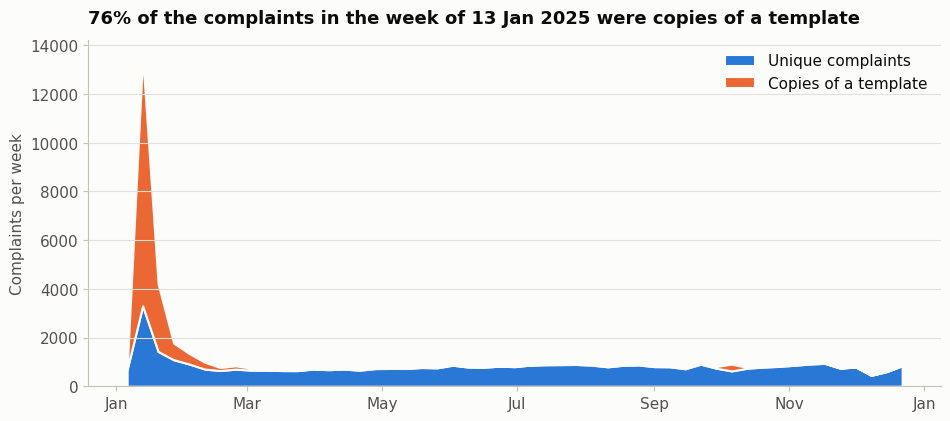

In [14]:
copies_weekly = (df[df["week"].isin(WEEKS)].groupby(["week", "is_copy"]).size()
                   .unstack(fill_value=0).reindex(index=WEEKS, columns=[False, True], fill_value=0))
peak_copy_share = copies_weekly.loc[peak_week, True] / copies_weekly.loc[peak_week].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(copies_weekly.index, copies_weekly[False], copies_weekly[True], colors=[SERIES[0], SERIES[1]],
             labels=["Unique complaints", "Copies of a template"], edgecolor=SURFACE, linewidth=1.5)
ax.set_title(f"{peak_copy_share:.0%} of the complaints in the week of {peak_week:%d %b %Y} were copies of a template")
ax.set_ylabel("Complaints per week")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper right")
save_fig(fig, "fig03_unique_vs_template_copies")

### Human check of the copy detector

Automatic agreement is not proof, so a person checks a sample. The cell below shows 20 flagged pairs, each from a *different* group. Random pairs would mostly come from the few huge campaigns and would be too easy to confirm.

Read each pair and count how many are really the same template or the same complaint filed twice. Then type that number into `HUMAN_CONFIRMED` and run the cell after the table again. The scorecard in section 10 uses it.

In [15]:
check_pairs = pairs.groupby("group").sample(1, random_state=SEED)
check_pairs = check_pairs.sample(min(20, len(check_pairs)), random_state=SEED)
human_check = pd.DataFrame({
    "complaint A": [" ".join(df.at[a, "text"].split()[:30]) for a in check_pairs["lo"]],
    "complaint B": [" ".join(df.at[b, "text"].split()[:30]) for b in check_pairs["hi"]],
    "cosine": check_pairs["cosine"].round(3).to_numpy(),
    "shared wording": check_pairs["overlap"].round(2).to_numpy(),
})
display(human_check)

,complaint A,complaint B,cosine,shared wording
0,I am writing to file a compliant against Navy Federal Credit Union regarding multiple overdraft fees I have incurred. Despite having sufficient funds whens transactions were authorized. I was charged,"I am writing to file a compliant against navy Federal Credit Union regarding multiple overdraft fees I have incurred. Despite having sufficient funds when transactions were authorized, I was charged",0.996,0.74
1,Account Number Ending In : Claim ID : Dispute Type : Debit - Unauthorized Transaction Date Error Reported : Claim Amount : $100.00 Account Number Ending In : Claim ID,Account Number Ending In : Claim ID : Dispute Type : Debit - Unauthorized Transaction Date Error Reported : Claim Amount : $100.00 Account Number Ending In : Claim ID,0.999,0.95
2,"I am seeking your help to investigate accounts from companies reporting late payments inaccurately. Upon reviewing my credit report, I discovered specific accounts marked with late payments, which is incorrect.","I am seeking your help to investigate accounts from companies reporting late payments inaccurately. Upon reviewing my credit report, I discovered specific accounts marked with late payments, which is incorrect.",1.000,1.00
3,Recently checking my credit report I notice that I had multiple collection and closed accounts. All of these accounts I have no knowledge of. They have been open and used,Recently checking my credit report I notice that I had multiple collection and closed accounts. All of these accounts I have no knowledge of. They have been open and used,0.974,0.92
4,"I state that the incorrect late payment entries on my accounts are in violation of 15 USC 1666. I have consistently paid on time, and any errors in this reporting","I state that the incorrect late payment entries on my accounts are in violation of 15 USC 1666. I have consistently paid on time, and any errors in this reporting",1.000,1.00
5,I fell victim to a phishing scam. I was called by someone impersonating a Wells Fargo Employee on . I was told that someone was trying to wire transfer money,I fell victim to a phishing scam. I was called by someone impersonating a Wells Fargo Employee on . I was told that someone was trying to wire transfer money,1.001,1.00
6,I recently reviewed my Early Warning Systems report and identified a fraudulent bank account that does not belong to me and that I do not recognize. This account is inaccurate,I recently reviewed my Early Warning Systems report and identified a fraudulent bank account that does not belong to me and that I do not recognize. This account is inaccurate,1.000,1.00
7,I am filing a complaint with the CFPB regarding Capital One 's failure to deposit my direct deposit from my employer and any other incoming deposits. Capital One has cited,I am filing a complaint with the CFPB regarding Capital One 's Failure to deposit my direct deposit from my employer and any other incoming deposits. Capital One has cited,1.000,0.93
8,"I have contacted the institution on numerous occassions asking them to provide me with proper consent that was was provided by me due to my information being brought, traded and","I have contacted the institution on numerous occassions asking them to provide me with proper consent that was was provided by me due to my information being brought, traded and",0.993,0.98
9,"I assert that the false late payment entries on my accounts violate the provisions of 15 USC 1666. My payments have always been made on time, and any errors in","I assert that the false late payment entries on my accounts violate the provisions of 15 USC 1666. My payments have always been made on time, and any errors in",1.001,1.00


In [16]:
HUMAN_CONFIRMED = 19
print("Pairs confirmed by a person:", HUMAN_CONFIRMED if HUMAN_CONFIRMED is not None else "not entered yet")

Pairs confirmed by a person: 19


## 5. Route: Word2Vec (main method 1)

**What it does.** It reads a complaint and sends it to one of the five product teams.

**How it would be used.** CFPB complaints come with a label: the consumer picks the product when filing. A bank's own channels (emails, web chats, call-centre notes) have no such label, and today a person reads each message to decide the team. So the router learns from the labelled CFPB complaints and is then applied to the bank's unlabelled messages.

**Design choices.**

- **Word2Vec trained on the complaints themselves** (Session 5, Assignment 2, Midterm), so it learns bank language: "zelle" sits next to "scam" and "cash_app", "escrow" sits next to "mortgage". It is trained only on the training split.
- **Word pairs** such as `direct_deposit` and `credit_card` are learned with gensim `Phrases`. This is the "n-gram values" from the brief.
- **Skip-gram, 100 dimensions, 10 passes**, the settings that fixed underfitting in the midterm.
- A complaint becomes the average of its word vectors.
- **Template copies are removed**, and the remaining unique complaints are split 80/20 by product. The test set is never seen during training.

**What we compare.**

1. **Keyword rules:** a JSON keyword list per team, which is what a simple rules engine does today.
2. **Word2Vec + taxonomy:** the same keyword list, matched by meaning instead of exact words. It uses no labels at all (the brief's taxonomy idea).
3. **Word2Vec + logistic regression:** learns from the labelled training complaints. This is our proposed router.
4. **LLM zero-shot:** `gpt-4o-mini` reads the complaint and picks a team (Session 6). It runs on 300 test complaints because it costs money per call.

The ground truth is the product the consumer chose when filing, which none of the models can see.

In [17]:
STOP_WORDS = set(ENGLISH_STOP_WORDS)


def tokenize(text):
    return [w for w in text.split() if len(w) > 2 and w not in STOP_WORDS]


df["tokens"] = df["clean"].map(tokenize)
unique = df[~df["is_copy"]]
train_idx, test_idx = train_test_split(unique.index.to_numpy(), test_size=0.2,
                                       stratify=unique["product"], random_state=SEED)
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)

phrases = Phrases(df.loc[train_idx, "tokens"].tolist(), min_count=max(5, round(20 * SCALE)), threshold=10)
bigram = phrases.freeze()
df["tokens"] = [list(bigram[t]) for t in df["tokens"]]

learned_pairs = Counter(t for doc in df.loc[train_idx, "tokens"] for t in doc if "_" in t)
print(f"Train: {len(train_idx):,} unique complaints | Test: {len(test_idx):,} unique complaints")
print("Most frequent word pairs:", ", ".join(w for w, _ in learned_pairs.most_common(20)))

Train: 34,886 unique complaints | Test: 8,722 unique complaints
Most frequent word pairs: credit_card, wells_fargo, cash_app, customer_service, bank_america, checking_account, debit_card, credit_report, multiple_times, phone_number, business_days, navy_federal, american_express, filing_complaint, credit_reporting, late_fees, credit_score, consumer_financial, consumer_protection, did_receive


In [18]:
start = time.time()
w2v = Word2Vec(sentences=df.loc[train_idx, "tokens"].tolist(), vector_size=100, window=5, min_count=5,
               sg=1, epochs=10, workers=4, seed=SEED)
print(f"Vocabulary: {len(w2v.wv):,} words and word pairs, trained in {time.time() - start:.0f} s")

PROBES = ["zelle", "overdraft", "repossession", "chargeback", "escrow", "cash_app", "direct_deposit", "late_fee"]
probe_table = pd.DataFrame({w: [f"{s} ({score:.2f})" for s, score in w2v.wv.most_similar(w, topn=5)]
                            for w in PROBES if w in w2v.wv}, index=[f"#{i}" for i in range(1, 6)]).T
display(probe_table)

Vocabulary: 13,949 words and word pairs, trained in 64 s


,#1,#2,#3,#4,#5
zelle,using_zelle (0.75),wrong_person (0.71),zelles (0.68),zell (0.65),accidentally_sent (0.62)
overdraft,overdraft_fees (0.82),overdraft_fee (0.80),charged_overdraft (0.79),overdrafts (0.76),overdraft_protection (0.74)
repossession,repo (0.79),repossessed_vehicle (0.79),repossession_vehicle (0.77),deficiency_balance (0.76),vehicle_repossessed (0.75)
chargeback,merchant (0.73),dispute (0.68),card_issuer (0.67),sided (0.67),merchants (0.66)
escrow,taxes_insurance (0.78),property_taxes (0.78),property_tax (0.76),homeowners_insurance (0.74),hazard_insurance (0.73)
cash_app,cashapp (0.88),cash_apps (0.71),chime (0.70),cashapps (0.67),square (0.65)
direct_deposit,direct_deposits (0.83),paychecks (0.78),paycheck (0.76),employer (0.76),payroll (0.74)
late_fee,late_fees (0.76),trailing (0.75),fee_assessed (0.70),assessed (0.69),waived (0.69)


In [19]:
def doc_vector(tokens):
    vectors = [w2v.wv[t] for t in tokens if t in w2v.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(w2v.vector_size, dtype="float32")


X_w2v = np.vstack([doc_vector(t) for t in df["tokens"]]).astype("float32")
y_product = df["product"].to_numpy()
y_test = y_product[test_idx]

TAXONOMY = {
    "Checking or savings account": ["checking", "savings", "overdraft", "debit", "deposit", "deposits",
                                    "atm", "branch", "withdrawal", "nsf"],
    "Credit card": ["credit_card", "card", "cards", "statement", "apr", "limit", "annual", "rewards",
                    "purchase", "merchant"],
    "Money transfer, virtual currency, or money service": ["zelle", "cash_app", "cashapp", "paypal", "venmo",
                                                          "wire", "transfer", "crypto", "bitcoin", "coinbase"],
    "Mortgage": ["mortgage", "escrow", "modification", "foreclosure", "refinance", "servicer", "home",
                 "property", "heloc", "appraisal"],
    "Vehicle loan or lease": ["car", "vehicle", "auto", "repossession", "repossessed", "lease", "dealership",
                              "dealer", "title", "repo"],
}
with open("taxonomy.json", "w") as f:
    json.dump(TAXONOMY, f, indent=2)

MOST_COMMON = pd.Series(y_product[train_idx]).mode()[0]


def keyword_route(tokens):
    bag = Counter(tokens + [part for t in tokens if "_" in t for part in t.split("_")])
    counts = {p: sum(bag[k] for k in words) for p, words in TAXONOMY.items()}
    best = max(counts, key=counts.get)
    return best if counts[best] > 0 else MOST_COMMON


centroids = np.vstack([np.mean([w2v.wv[k] for k in words if k in w2v.wv], axis=0) for words in TAXONOMY.values()])
centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)
TEAM_NAMES = np.array(list(TAXONOMY))


def taxonomy_route(X):
    X_norm = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-9, None)
    return TEAM_NAMES[np.argmax(X_norm @ centroids.T, axis=1)]


router = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
router.fit(X_w2v[train_idx], y_product[train_idx])

timings = {}
start = time.time()
pred_kw = np.array([keyword_route(t) for t in df.loc[test_idx, "tokens"]])
timings["Keyword rules (today)"] = (time.time() - start) / len(test_idx) * 1000
start = time.time()
pred_tax = taxonomy_route(X_w2v[test_idx])
timings["Word2Vec + taxonomy (no labels)"] = (time.time() - start) / len(test_idx) * 1000
start = time.time()
pred_lr = router.predict(X_w2v[test_idx])
timings["Word2Vec + logistic regression"] = (time.time() - start) / len(test_idx) * 1000
route_pred = dict(zip(test_idx, pred_lr))
print("Routing models trained and evaluated on", f"{len(test_idx):,}", "test complaints")

Routing models trained and evaluated on 8,722 test complaints


In [20]:
N_LLM = 60 if QUICK_RUN else 300
llm_rows = pd.Series(test_idx).sample(N_LLM, random_state=SEED).to_numpy()
ROUTER_SYSTEM = ("You route bank customer complaints to the team that owns the product. "
                 "Reply with exactly one of these team names and nothing else:\n" + "\n".join(PRODUCTS))
TEAM_KEYS = {"checking": PRODUCTS[0], "credit card": PRODUCTS[1], "money transfer": PRODUCTS[2],
             "mortgage": PRODUCTS[3], "vehicle": PRODUCTS[4]}


def parse_team(reply):
    reply = reply.lower()
    for key, product in TEAM_KEYS.items():
        if key in reply:
            return product
    return "Unparsed"


pred_llm = None
if RUN_OPENAI:
    pred_llm, tokens_in, tokens_out = [], 0, 0
    start = time.time()
    for row in llm_rows:
        reply, t_in, t_out = ask_openai(ROUTER_SYSTEM, " ".join(df.at[row, "text"].split()[:250]), max_tokens=20)
        pred_llm.append(parse_team(reply))
        tokens_in += t_in
        tokens_out += t_out
    pred_llm = np.array(pred_llm)
    timings["LLM zero-shot (gpt-4o-mini)"] = (time.time() - start) / N_LLM * 1000
    llm_cost_per_1000 = ((tokens_in * PRICE_PER_1M_TOKENS["input"] + tokens_out * PRICE_PER_1M_TOKENS["output"])
                         / 1e6 / N_LLM * 1000)
    print(f"LLM routed {N_LLM} complaints, {np.mean(pred_llm == 'Unparsed'):.1%} unparsed replies, "
          f"USD {llm_cost_per_1000:.3f} per 1,000 complaints")
else:
    print("LLM comparison skipped (RUN_OPENAI = False)")

LLM routed 300 complaints, 0.7% unparsed replies, USD 0.038 per 1,000 complaints


In [21]:
test_pos = {row: k for k, row in enumerate(test_idx)}
sub = np.array([test_pos[row] for row in llm_rows])
y_sub = y_test[sub]

routing_preds = {
    "Keyword rules (today)": pred_kw,
    "Word2Vec + taxonomy (no labels)": pred_tax,
    "Word2Vec + logistic regression": pred_lr,
}
routing_rows = []
for name, pred in routing_preds.items():
    routing_rows.append({"model": name,
                         "accuracy (all test)": accuracy_score(y_test, pred),
                         "macro-F1 (all test)": f1_score(y_test, pred, average="macro"),
                         f"accuracy ({N_LLM} sample)": accuracy_score(y_sub, pred[sub]),
                         "USD per 1,000": 0.0,
                         "ms per complaint": timings[name]})
if pred_llm is not None:
    routing_rows.append({"model": "LLM zero-shot (gpt-4o-mini)",
                         "accuracy (all test)": np.nan, "macro-F1 (all test)": np.nan,
                         f"accuracy ({N_LLM} sample)": accuracy_score(y_sub, pred_llm),
                         "USD per 1,000": llm_cost_per_1000,
                         "ms per complaint": timings["LLM zero-shot (gpt-4o-mini)"]})
routing_results = pd.DataFrame(routing_rows).set_index("model")
formats = {c: "{:.1%}" for c in routing_results.columns if "accuracy" in c or "F1" in c}
formats.update({"USD per 1,000": "{:.3f}", "ms per complaint": "{:.2f}"})
display(routing_results.style.format(formats, na_rep="–"))

ACC_KW = routing_results.loc["Keyword rules (today)", "accuracy (all test)"]
ACC_ROUTER = routing_results.loc["Word2Vec + logistic regression", "accuracy (all test)"]
F1_ROUTER = routing_results.loc["Word2Vec + logistic regression", "macro-F1 (all test)"]
report = pd.DataFrame(classification_report(y_test, pred_lr, output_dict=True)).T.loc[PRODUCTS]
report.index = [SHORT[p] for p in report.index]
display(report[["precision", "recall", "f1-score", "support"]].style.format(
    {"precision": "{:.2f}", "recall": "{:.2f}", "f1-score": "{:.2f}", "support": "{:,.0f}"}))

,accuracy (all test),macro-F1 (all test),accuracy (300 sample),"USD per 1,000",ms per complaint
model,,,,,
Keyword rules (today),70.6%,73.9%,71.0%,0.000,0.04
Word2Vec + taxonomy (no labels),69.6%,67.8%,67.0%,0.000,0.00
Word2Vec + logistic regression,81.2%,82.5%,80.3%,0.000,0.00
LLM zero-shot (gpt-4o-mini),–,–,77.7%,0.038,699.48


,precision,recall,f1-score,support
Checking/savings,0.80,0.76,0.78,"2,890"
Credit card,0.87,0.82,0.84,"2,525"
Money transfer,0.72,0.78,0.75,"1,642"
Mortgage,0.90,0.93,0.92,906
Vehicle loan,0.77,0.91,0.83,759


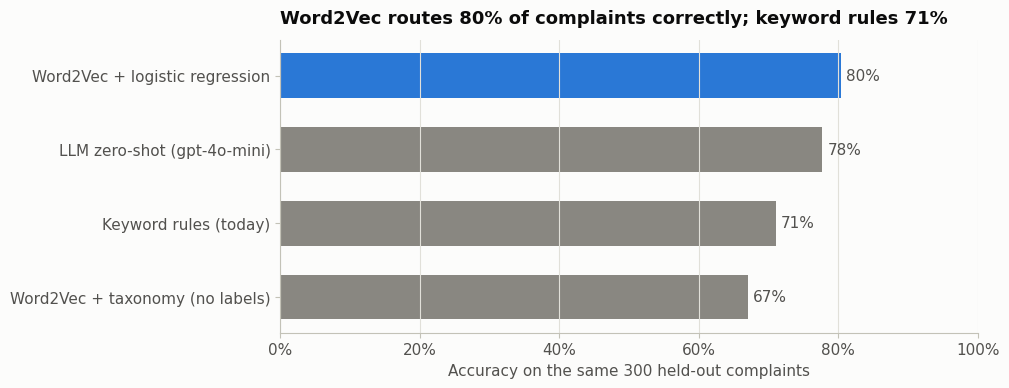

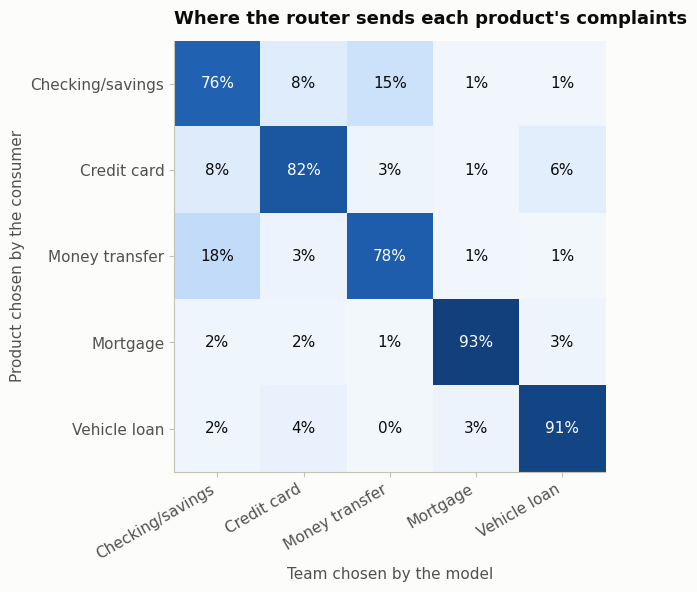

In [22]:
sample_acc = routing_results[f"accuracy ({N_LLM} sample)"].sort_values()
colors = [SERIES[0] if name == "Word2Vec + logistic regression" else MUTED for name in sample_acc.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(sample_acc.index, sample_acc.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in sample_acc.values], padding=4, color=INK_2)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title(f"Word2Vec routes {sample_acc['Word2Vec + logistic regression']:.0%} of complaints correctly; "
             f"keyword rules {sample_acc['Keyword rules (today)']:.0%}")
ax.set_xlabel(f"Accuracy on the same {N_LLM} held-out complaints")
save_fig(fig, "fig04_routing_accuracy")

cm = confusion_matrix(y_test, pred_lr, labels=PRODUCTS, normalize="true")
fig, ax = plt.subplots(figsize=(7, 5.6))
ax.imshow(cm, cmap=BLUES, vmin=0, vmax=1)
ax.grid(False)
labels = [SHORT[p] for p in PRODUCTS]
ax.set_xticks(range(5), labels, rotation=30, ha="right")
ax.set_yticks(range(5), labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else INK)
ax.set_xlabel("Team chosen by the model")
ax.set_ylabel("Product chosen by the consumer")
ax.set_title("Where the router sends each product's complaints")
save_fig(fig, "fig05_routing_confusion_matrix")

## 6. Prioritise: which complaints will end in a payout?

**What it does.** It gives every new complaint a payout risk, so the team reviews the riskiest ones first.

**Ground truth.** How the company really closed the complaint: "Closed with monetary relief" or not. Only about 1 complaint in 13 ends in a payout, so accuracy would be misleading: a model that always says "no payout" would be 93% accurate. We use these measures instead:

- **Payouts caught in the riskiest 20%:** if staff review the 20% highest-risk complaints, what share of all payouts do they catch? Random review catches 20%.
- **PR-AUC** (average precision) and **ROC-AUC**.

**Design choices.**

- Logistic regression on the Word2Vec complaint vector plus the product and the length of the story.
- Balanced class weights, because payouts are rare. The low-scoring example dealt with imbalance by throwing data away (down-sampling) and then reported accuracy.
- Compared with a product-only model, to show what the text adds beyond the product.

In [23]:
product_onehot = pd.get_dummies(df["product"]).reindex(columns=PRODUCTS, fill_value=0).to_numpy(dtype=float)
X_pay = np.hstack([X_w2v, product_onehot, np.log1p(df["n_words"].to_numpy(dtype=float))[:, None]])
y_pay = df["payout"].to_numpy()
y_pay_test = y_pay[test_idx]

product_model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(product_onehot[train_idx], y_pay[train_idx])
payout_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5))
payout_model.fit(X_pay[train_idx], y_pay[train_idx])

rng = np.random.default_rng(SEED)
jitter = rng.random(len(test_idx)) * 1e-9
payout_scores = {
    "Random review": rng.random(len(test_idx)),
    "Product only": product_model.predict_proba(product_onehot[test_idx])[:, 1] + jitter,
    "Word2Vec text + product": payout_model.predict_proba(X_pay[test_idx])[:, 1],
}


def caught_at(y, scores, share=0.2):
    top = np.argsort(-scores, kind="stable")[:int(round(len(scores) * share))]
    return y[top].sum() / y.sum()


payout_results = pd.DataFrame([{
    "model": name,
    "PR-AUC": average_precision_score(y_pay_test, s),
    "ROC-AUC": roc_auc_score(y_pay_test, s),
    "payouts caught in riskiest 20%": caught_at(y_pay_test, s),
    "payout rate in riskiest 20%": y_pay_test[np.argsort(-s, kind="stable")[:int(round(len(s) * 0.2))]].mean(),
} for name, s in payout_scores.items()]).set_index("model")
print(f"Payout rate in the test set: {y_pay_test.mean():.1%} ({y_pay_test.sum():,} payouts)")
display(payout_results.style.format("{:.3f}", subset=["PR-AUC", "ROC-AUC"])
                      .format("{:.1%}", subset=["payouts caught in riskiest 20%", "payout rate in riskiest 20%"]))
CAUGHT_20 = payout_results.loc["Word2Vec text + product", "payouts caught in riskiest 20%"]

Payout rate in the test set: 10.1% (885 payouts)


,PR-AUC,ROC-AUC,payouts caught in riskiest 20%,payout rate in riskiest 20%
model,,,,
Random review,0.102,0.497,20.7%,10.5%
Product only,0.143,0.652,28.8%,14.6%
Word2Vec text + product,0.266,0.787,52.2%,26.5%


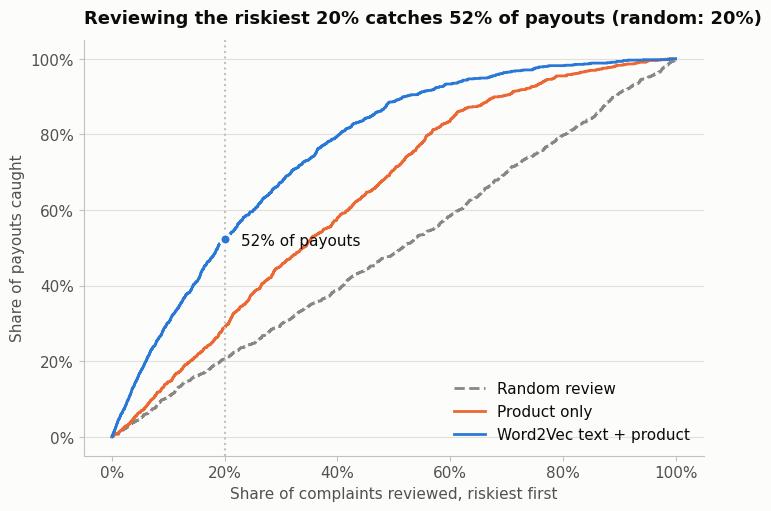

In [24]:
fig, ax = plt.subplots(figsize=(8, 5.4))
styles = {"Word2Vec text + product": (SERIES[0], "-"), "Product only": (SERIES[1], "-"), "Random review": (MUTED, "--")}
for name, s in payout_scores.items():
    order = np.argsort(-s, kind="stable")
    caught = np.concatenate([[0], np.cumsum(y_pay_test[order]) / y_pay_test.sum()])
    reviewed = np.linspace(0, 1, len(caught))
    color, line = styles[name]
    ax.plot(reviewed, caught, color=color, linestyle=line, label=name)
ax.axvline(0.2, color=AXIS, linestyle=":", linewidth=1.5)
ax.scatter([0.2], [CAUGHT_20], s=60, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3)
ax.annotate(f"{CAUGHT_20:.0%} of payouts", (0.2, CAUGHT_20), xytext=(12, -4), textcoords="offset points", color=INK)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of complaints reviewed, riskiest first")
ax.set_ylabel("Share of payouts caught")
ax.set_title(f"Reviewing the riskiest 20% catches {CAUGHT_20:.0%} of payouts (random: 20%)")
ax.legend(loc="lower right")
save_fig(fig, "fig06_payout_gains_curve")

### Fairness check

The CFPB tags complaints from older Americans and from servicemembers. These groups should not have their payouts missed more often than everyone else. This fairness measure is called "equal opportunity" (fairness is covered in Session 12). For each group we measure the share of its real payouts that land in the riskiest 20%. We count only a *shortfall* against untagged complaints, because a group that is caught more often is not harmed. The margin of error shows how much the number could move by chance, since the tagged groups are small.

In [25]:
risk = payout_scores["Word2Vec text + product"]
threshold = np.sort(risk)[::-1][int(round(len(risk) * 0.2)) - 1]
flagged = risk >= threshold
test_tags = df.loc[test_idx, "tags"].to_numpy()
groups = {
    "No tag": test_tags == "",
    "Older American": np.char.find(test_tags.astype(str), "Older American") >= 0,
    "Servicemember": np.char.find(test_tags.astype(str), "Servicemember") >= 0,
}
fairness = pd.DataFrame([{
    "group": name,
    "complaints": int(mask.sum()),
    "payouts": int(y_pay_test[mask].sum()),
    "share flagged as high risk": flagged[mask].mean(),
    "payouts caught": flagged[mask & (y_pay_test == 1)].mean() if y_pay_test[mask].sum() else np.nan,
} for name, mask in groups.items()]).set_index("group")
fairness["margin of error (95%)"] = 1.96 * np.sqrt(fairness["payouts caught"] * (1 - fairness["payouts caught"])
                                                   / fairness["payouts"].clip(lower=1))
fairness["shortfall vs no tag"] = (fairness.loc["No tag", "payouts caught"] - fairness["payouts caught"]).clip(lower=0)
FAIRNESS_GAP = fairness["shortfall vs no tag"].max()
display(fairness.style.format({"complaints": "{:,}", "payouts": "{:,}", "share flagged as high risk": "{:.1%}",
                               "payouts caught": "{:.1%}", "margin of error (95%)": "± {:.1%}",
                               "shortfall vs no tag": "{:.1%}"}, na_rep="–"))
print(f"Largest shortfall in payouts caught for a tagged group: {FAIRNESS_GAP * 100:.1f} percentage points")

,complaints,payouts,share flagged as high risk,payouts caught,margin of error (95%),shortfall vs no tag
group,,,,,,
No tag,"7,123",729,19.7%,52.5%,± 3.6%,0.0%
Older American,708,78,26.6%,59.0%,± 10.9%,0.0%
Servicemember,"1,071",96,18.5%,45.8%,± 10.0%,6.7%


Largest shortfall in payouts caught for a tagged group: 6.7 percentage points


## 7. Watch: LDA topic modeling (main method 2)

**What it does.** It finds the topics customers complain about and counts them week by week. When a topic jumps to 3× its normal weekly volume, managers get an alarm, and section 8 explains it.

**Design choices (the tuning the brief asks for).**

- **N-grams and number of topics:** single words, and single words plus learned word pairs, each tried with 6 to 20 topics. The most coherent combination wins (topic coherence c_v: the top words of a topic tend to appear together, so people can read it).
- **Minimum and maximum document frequency:** words in fewer than 10 complaints are dropped, and the share of complaints above which a word is too common to help (0.2, 0.4, 0.7) is tuned for the winning combination.
- **Untuned baseline:** only standard English stop words removed, no frequency filtering, 10 topics. This is the low-scoring example's setup, whose topics were full of "like", "get" and "im".
- **Words that describe no problem are removed:** contractions ("didnt", "cant"), words about the conversation itself ("told", "saying", "gave"), and the names of banks, apps and credit bureaus (Wells Fargo, Cash App, Zelle, Experian, ...). Names are removed so the topics describe *problems*, not companies; a surge at one bank still shows up, because its complaints share one problem. Our first run still had "didn" and "american express" among the top words, the same kind of mistake as the low-scoring example.
- Trained on unique complaints, so a campaign does not take over a topic. Then applied to *all* complaints, because the volume of copies is part of the alarm signal.

**Evaluation.**

1. Coherence compared with the untuned baseline. Coherence alone can be fooled, because filler words that appear everywhere also appear together, so we also measure:
2. Agreement with the CFPB's own issue labels (normalized mutual information): do the topics separate real problems? Compared with the untuned model and with random topics.
3. Whether the alarm fires after real, dated events in January 2025.
4. Whether watching topics adds anything to simply counting complaints, which needs no AI at all.

In [26]:
LDA_STOP = {
    "amount", "told", "said", "say", "says", "called", "call", "calls", "calling", "time", "times", "day", "days",
    "would", "could", "also", "get", "got", "getting", "back", "even", "one", "two", "still", "never", "want",
    "wanted", "made", "make", "know", "like", "since", "asked", "ask", "asking", "received", "receive", "help",
    "helped", "contacted", "contact", "phone", "number", "please", "company", "customer", "service", "just",
    "going", "went", "did", "does", "way", "need", "needed", "dont", "didnt", "able", "use", "used", "new",
    "month", "months", "year", "years", "week", "weeks", "today", "however", "multiple", "without", "another",
    "regarding", "request", "requested", "stated", "state", "let", "take", "took", "tried", "try", "trying",
    "sent", "send", "provided", "provide", "informed", "issue", "issues", "problem", "complaint", "complaints",
    "file", "filed", "filing", "cfpb", "bureau", "consumer", "financial", "protection", "letter", "email",
    "information", "thank", "thanks", "sincerely", "currently", "regards", "understand", "despite", "review",
    "consumers", "documentation", "required", "accordance", "pursuant", "formally", "writing", "concerns",
    "wells", "fargo", "wells_fargo", "bank_america", "america", "chase", "citi", "citibank", "capital",
    "capital_one", "navy", "federal", "navy_federal", "sofi", "synchrony", "discover", "american_express",
    "amex", "barclays", "pnc", "truist", "ally", "santander", "goldman", "sachs", "chime", "usaa", "citizens",
    "huntington", "regions", "comerica", "flagstar", "shellpoint", "rocket", "carvana", "westlake",
}
CONTRACTIONS = {"cant", "wont", "doesnt", "isnt", "wasnt", "werent", "arent", "havent", "hasnt", "hadnt", "couldnt",
                "wouldnt", "shouldnt", "ive", "youre", "theyre", "weve", "theyve", "youve", "ill"}
CONVERSATION = {"saying", "tell", "telling", "talk", "talked", "talking", "spoke", "speak", "gave", "give", "giving",
                "doing", "happened", "right", "explained", "explain"}
NAMES = {"paypal", "venmo", "zelle", "zelles", "cashapp", "cash_app", "coinbase", "robinhood", "experian", "equifax",
         "transunion", "bread", "cooper", "ocwen", "pennymac", "bridgecrest", "bmo", "usbank", "ews", "comenity",
         "bancorp", "affirm", "klarna", "afterpay", "varo", "american", "express", "bofa", "boa", "jpmorgan", "morgan",
         "keybank", "mtb", "suntrust", "lakeview", "nationstar", "newrez", "loancare", "carrington", "selene",
         "midfirst", "exeter", "toyota", "honda", "ford", "nissan", "hyundai", "kia", "tesla"}
LDA_STOP |= CONTRACTIONS | CONVERSATION | NAMES
NAME_PATTERN = re.compile(r"\b(cash ?app|american express|bank of america|wells fargo|capital one|navy federal|"
                          r"goldman sachs|early warning( services)?|credit one|td bank|us bank|fifth third|"
                          r"mr cooper|credit acceptance|apple card|apple pay|google pay)\b")


def lda_tokens(tokens):
    return [t for t in tokens if t not in LDA_STOP and not any(part in LDA_STOP for part in t.split("_"))]


def unigram_tokens(i):
    return [t for t in tokenize(NAME_PATTERN.sub(" ", df.at[i, "clean"])) if t not in LDA_STOP]


def build_corpus(texts, no_below, no_above, keep_n=20000):
    dictionary = Dictionary(texts)
    dictionary.filter_extremes(no_below=no_below, no_above=no_above, keep_n=keep_n)
    return dictionary, [dictionary.doc2bow(t) for t in texts]


def fit_lda(dictionary, corpus, k, passes=4):
    return LdaModel(corpus=corpus, id2word=dictionary, num_topics=k, passes=passes, chunksize=2000,
                    alpha="auto", eta="auto", random_state=SEED, eval_every=None)


def coherence(model, texts, dictionary):
    return CoherenceModel(model=model, texts=texts, dictionary=dictionary, coherence="c_v",
                          processes=1).get_coherence()


df["lda_tokens"] = df["tokens"].map(lda_tokens)
unique_ids = np.sort(unique.index.to_numpy())
TUNE_N = min(8000, len(unique_ids))
tune_ids = np.random.default_rng(SEED).choice(unique_ids, TUNE_N, replace=False)
tune_pairs = [df.at[i, "lda_tokens"] for i in tune_ids]
tune_single = [unigram_tokens(i) for i in tune_ids]
tune_raw = [tokenize(df.at[i, "clean"]) for i in tune_ids]
NO_BELOW = 10
print(f"Tuning on {TUNE_N:,} unique complaints")

Tuning on 8,000 unique complaints


Single words       k= 6: c_v = 0.504 (15 s)
Single words       k= 8: c_v = 0.490 (18 s)
Single words       k=10: c_v = 0.508 (16 s)
Single words       k=12: c_v = 0.524 (17 s)
Single words       k=15: c_v = 0.523 (18 s)
Single words       k=20: c_v = 0.490 (20 s)
Words + word pairs k= 6: c_v = 0.454 (14 s)
Words + word pairs k= 8: c_v = 0.454 (16 s)
Words + word pairs k=10: c_v = 0.483 (15 s)
Words + word pairs k=12: c_v = 0.462 (16 s)
Words + word pairs k=15: c_v = 0.474 (16 s)
Words + word pairs k=20: c_v = 0.457 (17 s)


,setting,coherence,agreement with CFPB issues (NMI)
0,"Single words, 12 topics, max share 0.2",0.545,0.215
1,"Single words, 12 topics, max share 0.4",0.524,0.256
2,"Single words, 12 topics, max share 0.7",0.484,0.230
3,"Untuned: standard stop words only, no filtering, 10 topics",0.480,0.229


Chosen: Single words, 12 topics, max share 0.2 (c_v 0.545, untuned 0.480)

Top words of the untuned topics:
  0: cash, app, paypal, money, card, service, cashapp, did, use, hotel
  1: vehicle, loan, wells, fargo, car, contract, financial, payments, dealership, documents
  2: financial, complaint, cfpb, despite, regarding, chase, resolution, consumer, failed, provide
  3: mortgage, payment, loan, payments, insurance, escrow, home, paid, property, pay
  4: dispute, charge, merchant, refund, transaction, charges, card, received, claim, did
  5: account, funds, bank, check, deposit, access, received, closed, told, days
  6: payment, fees, balance, fee, account, credit, card, charged, late, american
  7: account, money, told, bank, said, called, card, credit, did, sent
  8: credit, account, reporting, federal, information, act, consumer, report, provide, debt
  9: account, bank, card, fraud, credit, fraudulent, transactions, america, report, unauthorized


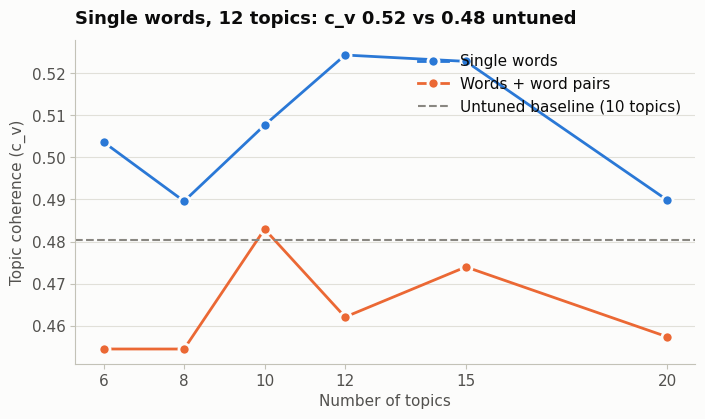

In [27]:
K_GRID = [6, 8, 10, 12, 15, 20]
TEXTS = {"single": tune_single, "pairs": tune_pairs}
LABELS = {"single": "Single words", "pairs": "Words + word pairs"}
tune_issues = df.loc[tune_ids, "issue"].to_numpy()


def issue_nmi(model, dictionary, texts):
    dominant = [max(model.get_document_topics(dictionary.doc2bow(t), minimum_probability=0.0), key=lambda x: x[1])[0]
                for t in texts]
    return normalized_mutual_info_score(tune_issues, dominant)


sweep = []
for kind, texts in TEXTS.items():
    d, c = build_corpus(texts, NO_BELOW, 0.4)
    for k in K_GRID:
        start = time.time()
        sweep.append({"texts": kind, "topics": k, "coherence": coherence(fit_lda(d, c, k), texts, d)})
        print(f"{LABELS[kind]:<18} k={k:>2}: c_v = {sweep[-1]['coherence']:.3f} ({time.time() - start:.0f} s)")
sweep = pd.DataFrame(sweep)
best = sweep.loc[sweep["coherence"].idxmax()]
BEST_K, best_kind = int(best["topics"]), best["texts"]

tuning = []
for no_above in [0.2, 0.4, 0.7]:
    d, c = build_corpus(TEXTS[best_kind], NO_BELOW, no_above)
    model = fit_lda(d, c, BEST_K)
    tuning.append({"setting": f"{LABELS[best_kind]}, {BEST_K} topics, max share {no_above}", "texts": best_kind,
                   "no_above": no_above, "topics": BEST_K, "coherence": coherence(model, TEXTS[best_kind], d),
                   "agreement with CFPB issues (NMI)": issue_nmi(model, d, TEXTS[best_kind])})
d, c = build_corpus(tune_raw, 1, 1.0, None)
untuned = fit_lda(d, c, 10)
tuning.append({"setting": "Untuned: standard stop words only, no filtering, 10 topics", "texts": "raw",
               "no_above": 1.0, "topics": 10, "coherence": coherence(untuned, tune_raw, d),
               "agreement with CFPB issues (NMI)": issue_nmi(untuned, d, tune_raw)})
tuning = pd.DataFrame(tuning)
display(tuning[["setting", "coherence", "agreement with CFPB issues (NMI)"]].style.format(
    {"coherence": "{:.3f}", "agreement with CFPB issues (NMI)": "{:.3f}"}))

UNTUNED_COHERENCE = tuning.loc[tuning["texts"] == "raw", "coherence"].iloc[0]
UNTUNED_NMI = tuning.loc[tuning["texts"] == "raw", "agreement with CFPB issues (NMI)"].iloc[0]
best_setting = tuning[tuning["texts"] != "raw"].sort_values("coherence").iloc[-1]
print(f"Chosen: {best_setting['setting']} (c_v {best_setting['coherence']:.3f}, untuned {UNTUNED_COHERENCE:.3f})")
print("\nTop words of the untuned topics:")
for t in range(10):
    print(f"  {t}: {', '.join(w for w, _ in untuned.show_topic(t, topn=10))}")

fig, ax = plt.subplots(figsize=(8, 4.2))
for color, kind in zip(SERIES, TEXTS):
    part = sweep[sweep["texts"] == kind]
    ax.plot(part["topics"], part["coherence"], color=color, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=LABELS[kind])
ax.axhline(UNTUNED_COHERENCE, color=MUTED, linestyle="--", linewidth=1.5, label="Untuned baseline (10 topics)")
ax.set_xticks(K_GRID)
ax.set_xlabel("Number of topics")
ax.set_ylabel("Topic coherence (c_v)")
ax.legend(loc="best")
ax.set_title(f"{LABELS[best_kind]}, {BEST_K} topics: c_v {best['coherence']:.2f} vs {UNTUNED_COHERENCE:.2f} untuned")
save_fig(fig, "fig07_lda_coherence")

In [28]:
use_pairs = best_setting["texts"] == "pairs"
texts_all = df["lda_tokens"].tolist() if use_pairs else [unigram_tokens(i) for i in range(len(df))]
NO_BELOW_FINAL = max(NO_BELOW, round(20 * SCALE))
final_dictionary, final_corpus = build_corpus([texts_all[i] for i in unique_ids], NO_BELOW_FINAL,
                                              best_setting["no_above"])
start = time.time()
lda = fit_lda(final_dictionary, final_corpus, BEST_K, passes=4 if QUICK_RUN else 8)
LDA_COHERENCE = coherence(lda, [texts_all[i] for i in tune_ids], final_dictionary)
print(f"Final LDA on {len(unique_ids):,} unique complaints in {time.time() - start:.0f} s, c_v = {LDA_COHERENCE:.3f}")

top_words = {t: [w for w, _ in lda.show_topic(t, topn=12)] for t in range(BEST_K)}
NAMING_SYSTEM = ("You name topics found in bank customer complaints. Reply with ONE short name of at most 4 words "
                 "that describes the customer's problem, for example: Overdraft fees. No lists, no line breaks.")
topic_names = {}
for t, words in top_words.items():
    if RUN_OPENAI:
        taken = ", ".join(topic_names.values()) or "none"
        name, _, _ = ask_openai(NAMING_SYSTEM, f"Most important words: {', '.join(words)}\nNames already used: {taken}",
                                max_tokens=12)
        name = name.strip().splitlines()[0].strip().strip('"').strip(".")
        topic_names[t] = " ".join(name.split()[:4])
    else:
        topic_names[t] = " / ".join(words[:3])
print(topic_names)

Final LDA on 43,608 unique complaints in 109 s, c_v = 0.539
{0: 'Late payment fees', 1: 'Deceptive practices', 2: 'Payment processing issues', 3: 'Account access issues', 4: 'Fraudulent transaction disputes', 5: 'Mortgage servicing problems', 6: 'Inaccurate reporting issues', 7: 'Lack of resolution assistance', 8: 'Refund dispute issues', 9: 'Vehicle repossession disputes', 10: 'Rewards program confusion', 11: 'Wallet transaction failures'}


In [29]:
bows = [final_dictionary.doc2bow(t) for t in texts_all]
theta = np.zeros((len(df), BEST_K), dtype="float32")
for i, bow in enumerate(bows):
    for t, p in lda.get_document_topics(bow, minimum_probability=0.0):
        theta[i, t] = p
df["topic"] = theta.argmax(axis=1)
df["topic_name"] = df["topic"].map(topic_names)

topic_table = pd.DataFrame({
    "topic name": pd.Series(topic_names),
    "top words": pd.Series({t: ", ".join(w[:10]) for t, w in top_words.items()}),
    "share of unique complaints": df.loc[unique_ids, "topic"].value_counts(normalize=True),
    "share of all complaints": df["topic"].value_counts(normalize=True),
}).fillna(0).sort_values("share of all complaints", ascending=False)
display(topic_table.style.format({"share of unique complaints": "{:.1%}", "share of all complaints": "{:.1%}"}))

,topic name,top words,share of unique complaints,share of all complaints
1,Deceptive practices,"regulation, act, failure, practices, written, deceptive, denial, unfair, conduct, failed",3.1%,17.8%
0,Late payment fees,"balance, payments, fees, late, fee, paid, charged, pay, statement, charges",13.0%,12.4%
3,Account access issues,"check, deposit, transfer, access, closed, checking, accounts, business, branch, hold",16.3%,11.9%
2,Payment processing issues,"pay, person, work, people, car, different, wrong, dollars, close, closed",14.6%,10.6%
4,Fraudulent transaction disputes,"fraud, transactions, transaction, unauthorized, fraudulent, charges, claim, investigation, debit, denied",12.9%,9.4%
11,Wallet transaction failures,"platform, failed, user, wallet, protect, recipient, claims, com, lost, using",1.6%,8.2%
7,Lack of resolution assistance,"explanation, resolution, matter, requesting, caused, clear, resolve, assistance, hardship, situation",8.7%,6.4%
6,Inaccurate reporting issues,"reporting, report, inaccurate, reported, accounts, identity, fcra, dispute, fair, theft",6.0%,5.8%
8,Refund dispute issues,"dispute, refund, merchant, charge, evidence, transaction, proof, claim, case, return",7.7%,5.6%
5,Mortgage servicing problems,"loan, mortgage, insurance, escrow, payments, home, servicing, foreclosure, property, servicer",6.8%,5.0%


Agreement with the CFPB issue labels (NMI): 0.224, random topics: 0.002


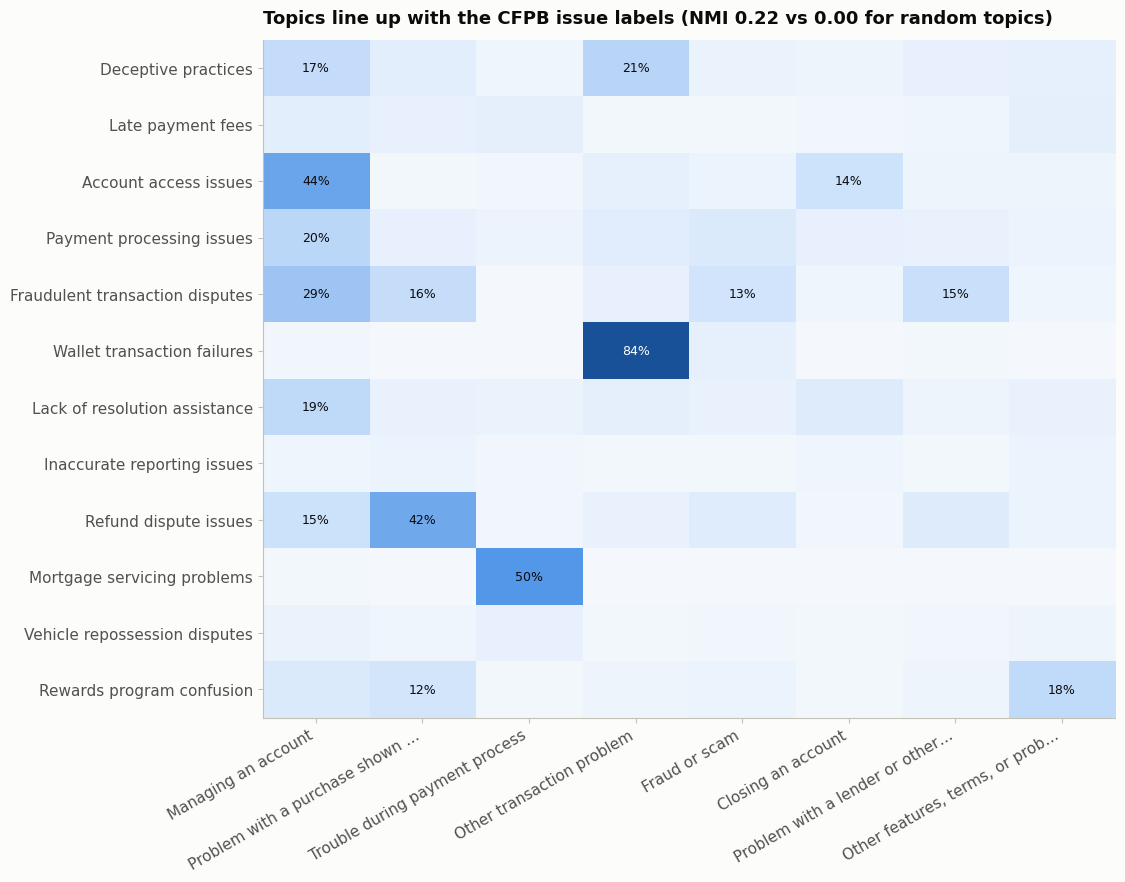

In [30]:
u = df.loc[unique_ids]
NMI = normalized_mutual_info_score(u["issue"], u["topic"])
NMI_RANDOM = normalized_mutual_info_score(u["issue"], np.random.default_rng(SEED).permutation(u["topic"].to_numpy()))
print(f"Agreement with the CFPB issue labels (NMI): {NMI:.3f}, random topics: {NMI_RANDOM:.3f}")

top_issues = u["issue"].value_counts().index[:8]
heat = pd.crosstab(u["topic"], u["issue"], normalize="index").reindex(columns=top_issues, fill_value=0)
heat = heat.reindex(topic_table.index, fill_value=0)
fig, ax = plt.subplots(figsize=(11, 0.55 * BEST_K + 2.2))
ax.imshow(heat.to_numpy(), cmap=BLUES, vmin=0, vmax=1, aspect="auto")
ax.grid(False)
ax.set_yticks(range(len(heat)), [topic_names[t] for t in heat.index])
ax.set_xticks(range(len(top_issues)), [i if len(i) <= 32 else i[:30] + "…" for i in top_issues], rotation=30, ha="right")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iat[i, j]
        if value >= 0.1:
            ax.text(j, i, f"{value:.0%}", ha="center", va="center", color="white" if value > 0.5 else INK, fontsize=9)
ax.set_title(f"Topics line up with the CFPB issue labels (NMI {NMI:.2f} vs {NMI_RANDOM:.2f} for random topics)")
save_fig(fig, "fig08_topics_vs_cfpb_issues")

In [31]:
topic_weekly = (df[df["week"].isin(WEEKS)].groupby(["week", "topic"]).size()
                  .unstack(fill_value=0).reindex(index=WEEKS, columns=range(BEST_K), fill_value=0))
normal = topic_weekly.median().clip(lower=1)
SPIKE_FACTOR = 3
MIN_ALARM = max(5, round(30 * SCALE))
times_normal = topic_weekly / normal
alarm_mask = (times_normal >= SPIKE_FACTOR) & (topic_weekly >= MIN_ALARM)
alarm_cells = list(zip(*np.where(alarm_mask.to_numpy())))
alarms = pd.DataFrame([{
    "week": WEEKS[w].strftime("%d %b %Y"), "topic": topic_names[t], "complaints": int(topic_weekly.iat[w, t]),
    "normal week": float(normal.iloc[t]), "times normal": float(times_normal.iat[w, t]),
} for w, t in alarm_cells])
print(f"{len(alarms)} alarms (a topic at {SPIKE_FACTOR}× its normal weekly volume or more)")
if len(alarms):
    display(alarms.style.format({"complaints": "{:,}", "normal week": "{:.0f}", "times normal": "{:.1f}×"}))

EVENTS = pd.DataFrame([
    ("2025-01-14", "CFPB sues Capital One over 360 Savings interest rates"),
    ("2025-01-16", "CFPB orders Block (Cash App) to pay up to USD 175 million over fraud handling"),
    ("2025-01-16", "Outage at vendor FIS delays Capital One deposits until 19 January"),
], columns=["date", "event"])
EVENTS["date"] = pd.to_datetime(EVENTS["date"])
alarm_weeks = sorted({WEEKS[w] for w, _ in alarm_cells})


def first_alarm_after(event_date, days=7):
    hits = [w for w in alarm_weeks if w + pd.Timedelta(days=6) >= event_date and w <= event_date + pd.Timedelta(days=days)]
    return hits[0] if hits else None


EVENTS["alarm week"] = [first_alarm_after(d) for d in EVENTS["date"]]
EVENTS["alarm within 7 days"] = EVENTS["alarm week"].notna()
EVENTS["alarm week"] = EVENTS["alarm week"].map(lambda w: w.strftime("%d %b %Y") if w is not None else "none")
display(EVENTS.assign(date=EVENTS["date"].dt.strftime("%d %b %Y")))
ALARM_OK = bool(EVENTS["alarm within 7 days"].all())

17 alarms (a topic at 3× its normal weekly volume or more)


,week,topic,complaints,normal week,times normal
0,13 Jan 2025,Late payment fees,"1,427",102,14.0×
1,13 Jan 2025,Deceptive practices,"6,370",31,205.5×
2,13 Jan 2025,Payment processing issues,737,106,7.0×
3,13 Jan 2025,Account access issues,622,130,4.8×
4,13 Jan 2025,Wallet transaction failures,"3,530",2,1765.0×
5,20 Jan 2025,Late payment fees,671,102,6.6×
6,20 Jan 2025,Deceptive practices,"1,850",31,59.7×
7,20 Jan 2025,Wallet transaction failures,608,2,304.0×
8,27 Jan 2025,Late payment fees,329,102,3.2×
9,27 Jan 2025,Deceptive practices,453,31,14.6×


,date,event,alarm week,alarm within 7 days
0,14 Jan 2025,CFPB sues Capital One over 360 Savings interest rates,13 Jan 2025,True
1,16 Jan 2025,CFPB orders Block (Cash App) to pay up to USD 175 million over fraud handling,13 Jan 2025,True
2,16 Jan 2025,Outage at vendor FIS delays Capital One deposits until 19 January,13 Jan 2025,True


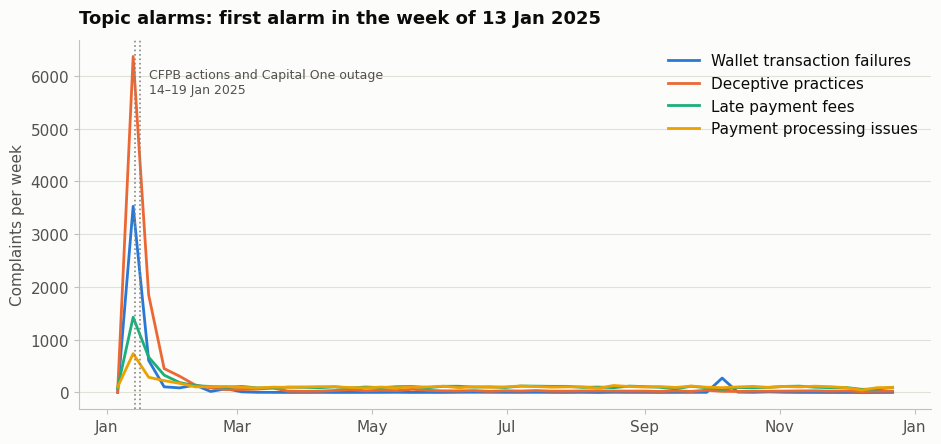

In [32]:
spiking = times_normal.max().sort_values(ascending=False).index[:4]
fig, ax = plt.subplots(figsize=(11, 4.8))
for color, t in zip(SERIES, spiking):
    ax.plot(topic_weekly.index, topic_weekly[t], color=color, label=topic_names[t])
for date in EVENTS["date"].unique():
    ax.axvline(date, color=MUTED, linestyle=":", linewidth=1.2)
ax.annotate("CFPB actions and Capital One outage\n14–19 Jan 2025", (EVENTS["date"].min(), ax.get_ylim()[1] * 0.92),
            xytext=(10, 0), textcoords="offset points", color=INK_2, fontsize=9, va="top")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("Complaints per week")
first_alarm = alarm_weeks[0].strftime("%d %b %Y") if alarm_weeks else "none"
ax.set_title(f"Topic alarms: first alarm in the week of {first_alarm}")
ax.legend(loc="upper right")
save_fig(fig, "fig09_topic_trends_and_alarms")

### Do topics add anything to simply counting complaints?

A bank could raise an alarm without any AI, by counting all complaints per week, or the complaints of each product team. The table compares those two simple alarms with the topic alarm, using the same rule (3× a normal week and at least the minimum number of complaints). For every week with any alarm, it shows how far above normal each way of counting was.

,busiest topic name,all complaints,busiest product team,busiest topic,alarm: all complaints,alarm: busiest product team,alarm: busiest topic
week,,,,,,,
13 Jan 2025,Wallet transaction failures,16.3×,76.8×,1765.0×,yes,yes,yes
20 Jan 2025,Wallet transaction failures,5.1×,20.6×,304.0×,yes,yes,yes
27 Jan 2025,Wallet transaction failures,2.1×,6.1×,53.5×,–,yes,yes
03 Feb 2025,Wallet transaction failures,1.6×,4.2×,43.5×,–,yes,yes
10 Feb 2025,Wallet transaction failures,1.2×,2.8×,70.5×,–,–,yes
24 Feb 2025,Wallet transaction failures,1.0×,1.6×,35.5×,–,–,yes
06 Oct 2025,Wallet transaction failures,1.1×,2.9×,136.5×,–,–,yes


Weeks with an alarm: all complaints 2, product teams 4, topics 7
Weeks that only the topic alarm catches: 10 Feb, 24 Feb, 06 Oct


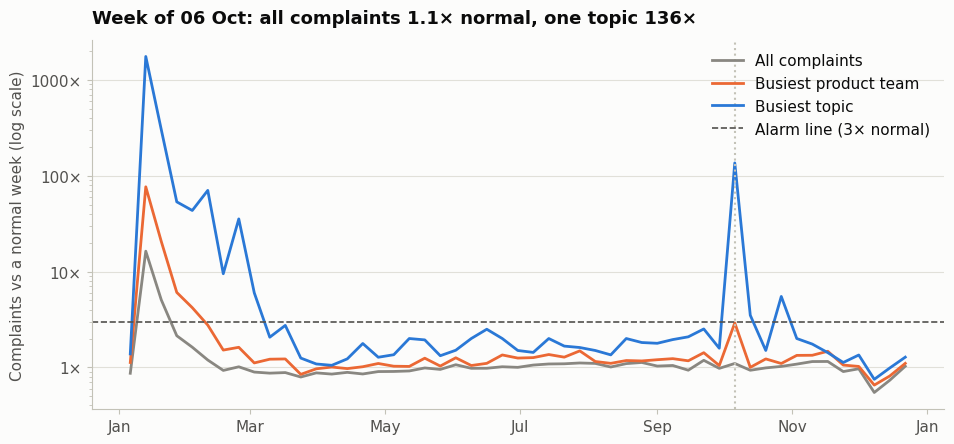

In [33]:
team_times = weekly / weekly.median().clip(lower=1)
total_times = weekly_total / weekly_total.median()
lens = pd.DataFrame({"all complaints": total_times,
                     "busiest product team": team_times.max(axis=1),
                     "busiest topic": times_normal.max(axis=1)})
lens_alarm = pd.DataFrame({
    "all complaints": (total_times >= SPIKE_FACTOR) & (weekly_total >= MIN_ALARM),
    "busiest product team": ((team_times >= SPIKE_FACTOR) & (weekly >= MIN_ALARM)).any(axis=1),
    "busiest topic": alarm_mask.any(axis=1),
})
any_alarm = lens_alarm.any(axis=1)
comparison = lens[any_alarm].copy()
comparison.insert(0, "busiest topic name", [topic_names[t] for t in times_normal[any_alarm].idxmax(axis=1)])
for col in lens_alarm.columns:
    comparison[f"alarm: {col}"] = np.where(lens_alarm.loc[any_alarm, col], "yes", "–")
comparison.index = comparison.index.strftime("%d %b %Y")
comparison.index.name = "week"
display(comparison.style.format({c: "{:.1f}×" for c in lens.columns}))

HIDDEN_FROM_COUNTS = [w for w in WEEKS if lens_alarm.at[w, "busiest topic"]
                      and not lens_alarm.at[w, "all complaints"] and not lens_alarm.at[w, "busiest product team"]]
SHOWCASE_WEEK = max(HIDDEN_FROM_COUNTS, key=lambda w: lens.at[w, "busiest topic"]) if HIDDEN_FROM_COUNTS else None
SHOWCASE_TOPIC = topic_names[times_normal.loc[SHOWCASE_WEEK].idxmax()] if SHOWCASE_WEEK is not None else None
print(f"Weeks with an alarm: all complaints {int(lens_alarm['all complaints'].sum())}, "
      f"product teams {int(lens_alarm['busiest product team'].sum())}, topics {int(lens_alarm['busiest topic'].sum())}")
print("Weeks that only the topic alarm catches:", ", ".join(f"{w:%d %b}" for w in HIDDEN_FROM_COUNTS) or "none")

fig, ax = plt.subplots(figsize=(11, 4.8))
for color, col in zip([MUTED, SERIES[1], SERIES[0]], lens.columns):
    ax.plot(lens.index, lens[col].clip(lower=0.1), color=color, label=col.capitalize())
ax.axhline(SPIKE_FACTOR, color=INK_2, linestyle="--", linewidth=1.2, label=f"Alarm line ({SPIKE_FACTOR}× normal)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("Complaints vs a normal week (log scale)")
ax.legend(loc="upper right")
if SHOWCASE_WEEK is not None:
    ax.axvline(SHOWCASE_WEEK, color=AXIS, linestyle=":", linewidth=1.5)
    ax.set_title(f"Week of {SHOWCASE_WEEK:%d %b}: all complaints {lens.at[SHOWCASE_WEEK, 'all complaints']:.1f}× normal, "
                 f"one topic {lens.at[SHOWCASE_WEEK, 'busiest topic']:.0f}×")
else:
    ax.set_title("Weekly complaints against a normal week, counted three ways")
save_fig(fig, "fig10_alarm_three_ways")

### What was behind each alarm?

An alarm is only useful if something real is behind it. For every alarm we check two things in the data: whether one of the dated January events happened that week or the week before, and whether at least half of the alarm's complaints belong to a copy campaign found in section 4. Section 8 then reads the complaints behind each alarm.

In [34]:
REVIEW_COLUMNS = ["week", "topic", "topic name", "complaints", "times normal", "main company", "main company share",
                  "share in copy campaigns", "explained by"]
review_rows = []
for w, t in alarm_cells:
    week = WEEKS[w]
    rows = df[(df["week"] == week) & (df["topic"] == t)]
    companies = rows["company"].value_counts()
    near_event = ((EVENTS["date"] >= week - pd.Timedelta(days=7)) & (EVENTS["date"] <= week + pd.Timedelta(days=6))).any()
    campaign_share = float((rows["group_size"] >= CAMPAIGN_MIN).mean())
    review_rows.append([week, int(t), topic_names[t], len(rows), float(times_normal.iat[w, t]), companies.index[0],
                        companies.iloc[0] / len(rows), campaign_share,
                        "dated event" if near_event else ("copy campaign" if campaign_share >= 0.5 else "not explained yet")])
alarm_review = pd.DataFrame(review_rows, columns=REVIEW_COLUMNS)
ALARMS_EXPLAINED = int((alarm_review["explained by"] != "not explained yet").sum())
print(f"{ALARMS_EXPLAINED} of {len(alarm_review)} alarms are explained by a dated event or a copy campaign")
if len(alarm_review):
    display(alarm_review.drop(columns="topic").assign(week=alarm_review["week"].dt.strftime("%d %b %Y")).style.format(
        {"complaints": "{:,}", "times normal": "{:.1f}×", "main company share": "{:.0%}", "share in copy campaigns": "{:.0%}"}))

16 of 17 alarms are explained by a dated event or a copy campaign


,week,topic name,complaints,times normal,main company,main company share,share in copy campaigns,explained by
0,13 Jan 2025,Late payment fees,"1,427",14.0×,NAVY FEDERAL CREDIT UNION,84%,69%,dated event
1,13 Jan 2025,Deceptive practices,"6,370",205.5×,"Block, Inc.",92%,96%,dated event
2,13 Jan 2025,Payment processing issues,737,7.0×,"Early Warning Services, LLC",26%,0%,dated event
3,13 Jan 2025,Account access issues,622,4.8×,CAPITAL ONE FINANCIAL CORPORATION,62%,1%,dated event
4,13 Jan 2025,Wallet transaction failures,"3,530",1765.0×,"Early Warning Services, LLC",98%,87%,dated event
5,20 Jan 2025,Late payment fees,671,6.6×,NAVY FEDERAL CREDIT UNION,77%,64%,dated event
6,20 Jan 2025,Deceptive practices,"1,850",59.7×,"Block, Inc.",96%,95%,dated event
7,20 Jan 2025,Wallet transaction failures,608,304.0×,"Early Warning Services, LLC",96%,86%,dated event
8,27 Jan 2025,Late payment fees,329,3.2×,NAVY FEDERAL CREDIT UNION,56%,47%,not explained yet
9,27 Jan 2025,Deceptive practices,453,14.6×,"Block, Inc.",94%,90%,copy campaign


## 8. Explain: why is this problem surging? (main method 3)

**What it does.** When a topic alarm fires, a manager wants to know what is behind it before deciding what to do. They click the alarm, or ask in plain English, for example *"What were Capital One customers complaining about in the week of 13 January?"*, and the assistant answers from that week's complaints and cites them. It works like our Assignment 3 RAG pipeline:

1. **Agent** (Qwen3-4B, Session 8): reads the question and returns JSON: whether to search, a short search query, and the filters the question asks for (dates, product, company, topic).
2. **Filtered search** (Session 7): FAISS on the sentence embeddings from section 4, limited with `IDSelectorBatch` to the complaints that match the filters, plus BM25 on the same complaints. A cross-encoder re-ranks the candidates, as in Assignment 3.
3. **"I don't know"**: if no complaint matches the filters, or even the best one is not relevant enough, the assistant says so instead of guessing.
4. **Brief** (Qwen3-4B): what customers report, which companies and when, citing complaints as [1], [2], ... Copies of one template are shown once, with the number of times they were filed. The Scale line (how many complaints match, how many are copies) is counted from the database, not written by the model.

**What we learned from our first version.** Our first RAG assistant wrote a brief for every single complaint, ending with a "Next step" line of advice for the agent. Its RAGAs faithfulness was 0.75, below the 0.80 target, and 0.94 when that line was left out: advice cannot be backed by any complaint. The new brief states only facts from the complaints; deciding what to do stays with the manager. For each single complaint, the agent now gets a case card with real records instead (8.2).

**Why an open model writes and GPT only grades.** In production Qwen3-4B runs on the bank's own GPU, so complaint text does not leave the bank. `gpt-4o-mini` is only used to evaluate, on public CFPB text, and a model should not grade its own answers.

**Evaluation.**

- **Search engine** (8.1): precision@5 for finding past cases with the same issue, compared with keyword search, plain FAISS, a filter on the routed team, hybrid search, and the Word2Vec document vectors from our midterm.
- **Agent** (8.3): a test suite in the style of Assignment 4: 16 questions with known correct filters, a first prompt (v1) against an improved prompt (v2), and the share of checks each passes.
- **Briefs** (8.5): two brief versions (v1 and v2, see 8.4), one brief per alarm, with and without the filters. Does it name the company behind the surge (taken from the complaint records, never given to the model as a label)? Are the three January events named in that week's briefs? Then RAGAs faithfulness and answer relevancy, and an LLM judge spot-checked by a person.

### 8.1 Choosing the search engine

The assistant first needs good search. We test search methods on a task with a known answer: for held-out complaints, find the 5 most similar past complaints (training split) and count how many have the same CFPB issue. The knowledge base is the training split only, so a complaint never finds itself. The newest row is our midterm's method: each complaint as the average of its Word2Vec vectors, compared by cosine similarity.

In [35]:
kb_ids = train_idx
kb_index = faiss.IndexFlatIP(emb.shape[1])
kb_index.add(emb[kb_ids])
kb_product = df.loc[kb_ids, "product"].to_numpy()
ALLOWED = {p: np.where(kb_product == p)[0].astype("int64") for p in PRODUCTS}


def dense_search(row, product=None, k=5):
    query = emb[row:row + 1]
    if product is None:
        _, ids = kb_index.search(query, k)
    else:
        allowed = ALLOWED[product]
        selector = faiss.IDSelectorBatch(len(allowed), faiss.swig_ptr(allowed))
        _, ids = kb_index.search(query, k, params=faiss.SearchParameters(sel=selector))
    return [int(kb_ids[i]) for i in ids[0] if i != -1]


start = time.time()
bm25 = BM25Okapi([df.at[i, "tokens"] for i in kb_ids])
print(f"Knowledge base: {len(kb_ids):,} past complaints, BM25 index built in {time.time() - start:.0f} s")


bm25_cache = {}


def bm25_search(row, k=5, depth=50):
    if row not in bm25_cache:
        scores = bm25.get_scores(list(dict.fromkeys(df.at[row, "tokens"]))[:60])
        bm25_cache[row] = [int(kb_ids[i]) for i in np.argsort(-scores)[:depth]]
    return bm25_cache[row][:k]


def hybrid_search(row, k=5, depth=50, c=60):
    fused = {}
    for ranking in (dense_search(row, k=depth), bm25_search(row, k=depth)):
        for rank, hit in enumerate(ranking):
            fused[hit] = fused.get(hit, 0.0) + 1.0 / (c + rank + 1)
    return sorted(fused, key=fused.get, reverse=True)[:k]


def random_search(row, product, k=5):
    return [int(kb_ids[i]) for i in rng.choice(ALLOWED[product], k, replace=False)]


kb_w2v = X_w2v[kb_ids] / np.clip(np.linalg.norm(X_w2v[kb_ids], axis=1, keepdims=True), 1e-9, None)
w2v_index = faiss.IndexFlatIP(kb_w2v.shape[1])
w2v_index.add(kb_w2v.astype("float32"))


def word2vec_search(row, k=5):
    query = X_w2v[row:row + 1] / max(float(np.linalg.norm(X_w2v[row])), 1e-9)
    _, ids = w2v_index.search(query.astype("float32"), k)
    return [int(kb_ids[i]) for i in ids[0] if i != -1]

Knowledge base: 34,886 past complaints, BM25 index built in 1 s


,precision@5 (same issue),precision@5 (same product),ms per query
method,,,
Random past cases (routed team),0.204,0.802,0.1
Keyword search (BM25),0.351,0.699,385.0
FAISS (meaning),0.390,0.767,6.8
FAISS + routed-team filter,0.405,0.802,4.8
Hybrid FAISS + BM25,0.391,0.745,5.8
Word2Vec document vectors (midterm),0.355,0.708,0.7


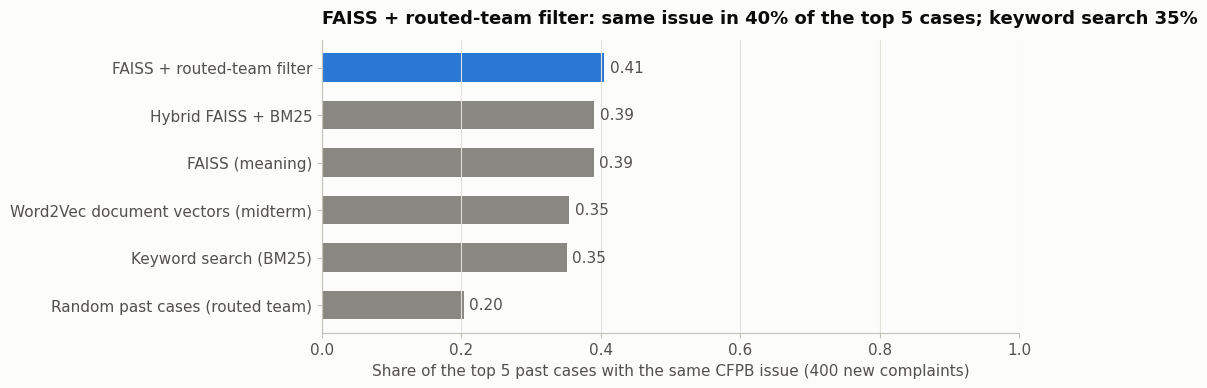

**Chosen for the case card below: FAISS + routed-team filter** (precision@5 0.41, BM25 0.35). Our midterm's Word2Vec document vectors reach 0.35: averaging word vectors loses detail that sentence embeddings keep.

In [36]:
EVAL_N = 100 if QUICK_RUN else 400
eval_rows = pd.Series(test_idx).sample(EVAL_N, random_state=SEED).to_numpy()
rng = np.random.default_rng(SEED)
search_methods = {
    "Random past cases (routed team)": lambda r: random_search(r, route_pred[r]),
    "Keyword search (BM25)": lambda r: bm25_search(r),
    "FAISS (meaning)": lambda r: dense_search(r),
    "FAISS + routed-team filter": lambda r: dense_search(r, route_pred[r]),
    "Hybrid FAISS + BM25": lambda r: hybrid_search(r),
    "Word2Vec document vectors (midterm)": lambda r: word2vec_search(r),
}


def share_same(row, hits, field):
    return np.mean([df.at[h, field] == df.at[row, field] for h in hits]) if hits else 0.0


retrieval_rows = []
for name, search in search_methods.items():
    start = time.time()
    results = [(r, search(r)) for r in eval_rows]
    retrieval_rows.append({"method": name,
                           "precision@5 (same issue)": np.mean([share_same(r, h, "issue") for r, h in results]),
                           "precision@5 (same product)": np.mean([share_same(r, h, "product") for r, h in results]),
                           "ms per query": (time.time() - start) / EVAL_N * 1000})
retrieval = pd.DataFrame(retrieval_rows).set_index("method")
display(retrieval.style.format({"precision@5 (same issue)": "{:.3f}", "precision@5 (same product)": "{:.3f}",
                                "ms per query": "{:.1f}"}))
P5_BEST_NAME = retrieval.drop(index="Random past cases (routed team)")["precision@5 (same issue)"].idxmax()
P5_OURS = retrieval.loc[P5_BEST_NAME, "precision@5 (same issue)"]
P5_W2V = retrieval.loc["Word2Vec document vectors (midterm)", "precision@5 (same issue)"]
P5_FAISS = retrieval.loc["FAISS (meaning)", "precision@5 (same issue)"]
P5_BM25 = retrieval.loc["Keyword search (BM25)", "precision@5 (same issue)"]

values = retrieval["precision@5 (same issue)"].sort_values()
colors = [SERIES[0] if name == P5_BEST_NAME else MUTED for name in values.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(values.index, values.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in values.values], padding=4, color=INK_2)
ax.set_xlim(0, 1)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Share of the top 5 past cases with the same CFPB issue ({EVAL_N} new complaints)")
ax.set_title(f"{P5_BEST_NAME}: same issue in {P5_OURS:.0%} of the top 5 cases; keyword search {P5_BM25:.0%}")
save_fig(fig, "fig11_retrieval_precision")

w2v_note = ("averaging word vectors loses detail that sentence embeddings keep" if P5_W2V < P5_FAISS
            else "on par with sentence embeddings")
display(Markdown(f"**Chosen for the case card below: {P5_BEST_NAME}** (precision@5 {P5_OURS:.2f}, BM25 {P5_BM25:.2f}). "
                 f"Our midterm's Word2Vec document vectors reach {P5_W2V:.2f}: {w2v_note}."))

### 8.2 Case card for an agent

For each new complaint, the agent sees the team chosen by the router (section 5), the payout risk (section 6), and the five most similar past complaints with how each one was closed. This part uses no LLM: the past outcomes are real records, so nothing can be made up. It works as a content-based recommender of past cases (Session 10).

In [37]:
case_search = search_methods[P5_BEST_NAME]
risk_by_row = dict(zip(test_idx, payout_scores["Word2Vec text + product"]))
risk_cut = np.quantile(payout_scores["Word2Vec text + product"], [0.5, 0.8])


def risk_label(row):
    score = risk_by_row[row]
    return "high" if score >= risk_cut[1] else ("medium" if score >= risk_cut[0] else "low")


def case_card(row):
    hits = case_search(row)
    similar = pd.DataFrame({
        "complaint_id": df.loc[hits, "complaint_id"].to_numpy(),
        "issue": df.loc[hits, "issue"].to_numpy(),
        "closed with": df.loc[hits, "company_response"].to_numpy(),
        "opening words": [(" ".join(df.at[h, "text"].split()[:14]) + " ...").replace("$", "USD ") for h in hits],
    })
    paid = int((similar["closed with"] == "Closed with monetary relief").sum())
    header = (f"**Complaint {df.at[row, 'complaint_id']}** ({df.at[row, 'date_received']:%d %b %Y}, {df.at[row, 'company']})\n\n"
              f"> {' '.join(df.at[row, 'text'].split()[:70])} ...\n\n"
              f"**Routed to:** {SHORT[route_pred[row]]} (consumer chose: {SHORT[df.at[row, 'product']]}) · "
              f"**Payout risk:** {risk_label(row)} · "
              f"**Similar past cases closed with money paid back:** {paid} of {len(hits)}")
    display(Markdown(header.replace("$", "USD ")))
    display(similar)


card_rows = [next((r for r in eval_rows if risk_label(r) == level), eval_rows[0]) for level in ("high", "low")]
for row in card_rows:
    case_card(row)

**Complaint 15777178** (07 Sep 2025, UNITED SERVICES AUTOMOBILE ASSOCIATION)

> This complaint provides additional information regarding the previous complaint I filed on ( No. ). It relates to the same transactions. In early , I noticed approximately USD 1000.00 in charges on my USAA Amex Card for suspicious purchases. In reviewing my account information, I noticed several purchases on and from ( i ) a in NY, ( ii ) the , ( iii ) a in , Pennsylvania, and ( ...

**Routed to:** Credit card (consumer chose: Credit card) · **Payout risk:** high · **Similar past cases closed with money paid back:** 3 of 5

,complaint_id,issue,closed with,opening words
0,16282343,Problem with a purchase shown on your statement,Closed with explanation,"Hello, this is my ( FIFTH ) complaint regarding Amex 's illegal actions. Previous ..."
1,18276041,Problem with a purchase shown on your statement,Closed with monetary relief,"On , a charge of USD 530.00 was made by to my USAA credit card. ..."
2,13437256,Problem with a purchase shown on your statement,Closed with monetary relief,"To Whom It May Concern, I am writing to file a formal complaint against ..."
3,13969877,Fees or interest,Closed with explanation,"Name of Complainant : Complaint Against : USAA , Preamble : This complaint is ..."
4,13920142,Problem with a purchase shown on your statement,Closed with monetary relief,I am submitting this formal complaint against American Express ( Amex ) due to ...


**Complaint 11658278** (17 Jan 2025, Block, Inc.)

> Cashapp and allowed and charged for fraudulent transactions ...

**Routed to:** Money transfer (consumer chose: Money transfer) · **Payout risk:** low · **Similar past cases closed with money paid back:** 0 of 5

,complaint_id,issue,closed with,opening words
0,11650706,Unauthorized transactions or other transaction problem,Closed with explanation,Cashapp allowed unauthorized transactions in my account ...
1,11500950,Unauthorized transactions or other transaction problem,Closed with explanation,"Cash App failed to protect my account from hackers, resulting in USD 24000.00 unauthorized transactions ..."
2,11751611,"Managing, opening, or closing your mobile wallet account",Closed with explanation,"Cash app, allowed hacking theirs advised i was under fraud stil refused to provide ..."
3,11633060,Other transaction problem,Closed with explanation,- Cash App Transactions. Multiple fraud from other accounts. ...
4,14423667,Fraud or scam,Closed with explanation,There was a total of cashapp transfers to a person I have never met. ...


### 8.3 The agent: from a question to search filters

As in Assignment 3, a routing agent reads the manager's question and returns JSON: whether to search, a short search query, and the filters the question asks for. Assignment 3 filtered by source and year; here the filters are dates, product, company and the LDA topic, so the topics from section 7 become a way to search.

The agent is tested the way we tested the chatbot prompt in Assignment 4: a fixed set of questions with known answers, a first prompt (v1) and an improved prompt (v2) with rules and examples, and automatic checks. Qwen3-4B decodes greedily (no sampling), so a second run gives the same answers and one run per prompt is enough.

In [38]:
LLM_MODEL = "Qwen/Qwen3-4B"
RERANKER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"

if RUN_QWEN:
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL)
    llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype=torch.float16).to(DEVICE)
reranker = CrossEncoder(RERANKER_MODEL, device=DEVICE)


def generate(messages, max_new_tokens=300):
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        output = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    text = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()


print("Writer and agent:", LLM_MODEL if RUN_QWEN else "switched off (needs a GPU)", "| Re-ranker:", RERANKER_MODEL)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Writer and agent: Qwen/Qwen3-4B | Re-ranker: cross-encoder/ms-marco-MiniLM-L-6-v2


In [39]:
PRODUCT_BY_NAME = {**{SHORT[p].lower(): p for p in PRODUCTS}, **{p.lower(): p for p in PRODUCTS}}
PRODUCT_LIST = "\n".join(f"- {SHORT[p]}" for p in PRODUCTS)
TOPIC_LIST = "\n".join(f"- {name}" for name in topic_names.values())
TOPIC_BY_NAME = {name.lower(): t for t, name in topic_names.items()}

AGENT_PROMPT_V1 = """You help search bank complaints. Read the question and reply with JSON with the keys
retrieve, search_query, date_from, date_to, product, company, topic. Use null when a key does not apply."""

AGENT_PROMPT_V2 = f"""You are the routing agent of a complaint analysis assistant for a bank.
The assistant can search US consumer complaints received from 1 January to 31 December 2025, about these products:
{PRODUCT_LIST}
Each complaint also has one of these topics, found by topic modeling:
{TOPIC_LIST}

Decide whether the user's message needs a search, and which filters it asks for.
- Search for EVERY question about complaints, customers, companies or products. Do not search for greetings,
  thanks or small talk.
- Only set a filter when the question explicitly asks for it. Never guess a product, company or topic that the
  question does not name.
- Copy "product" exactly from the product list and "topic" exactly from the topic list.
- Banks, credit unions and payment apps (for example Zelle, Cash App, PayPal, Chime) are companies, not products.
- Dates are in 2025 unless the question names another year. A week starts on Monday: "the week of 13 January" is
  2025-01-13 to 2025-01-19. A month is its first to its last day. "Early October" is 2025-10-01 to 2025-10-10.
- If the question asks about a period outside 2025, still set "retrieve" to true and put that period in the dates;
  the system will report that it has no data.

Reply with ONLY a JSON object with these keys:
  "retrieve": true or false
  "search_query": a short keyword query for the problem, without the company, product and dates
                  (those go in the filters), or "" if retrieve is false
  "date_from": "YYYY-MM-DD" or null
  "date_to": "YYYY-MM-DD" or null
  "product": one product from the list, or null
  "company": the company name as the user wrote it, or null
  "topic": one topic from the list, or null

Examples:
User: Hi, who are you?
{{"retrieve": false, "search_query": "", "date_from": null, "date_to": null, "product": null, "company": null, "topic": null}}
User: Why were Capital One customers missing direct deposits in the week of 13 January?
{{"retrieve": true, "search_query": "direct deposit not received", "date_from": "2025-01-13", "date_to": "2025-01-19", "product": null, "company": "Capital One", "topic": null}}
User: What problems did mortgage customers have with escrow in March?
{{"retrieve": true, "search_query": "escrow problems", "date_from": "2025-03-01", "date_to": "2025-03-31", "product": "Mortgage", "company": null, "topic": null}}"""

GENERIC = {"bank", "inc", "financial", "corporation", "corp", "company", "co", "na", "n", "a", "llc", "the", "of",
           "services", "holdings", "holding", "group", "usa", "us", "national", "association"}
COMPANY_ALIASES = {"zelle": "early warning", "cash app": "block", "cashapp": "block", "square": "block",
                   "chase": "jpmorgan chase", "amex": "american express", "citi": "citibank", "bofa": "america",
                   "usaa": "united services automobile"}


def name_words(name):
    return [w for w in re.sub(r"[^a-z0-9 ]", " ", name.lower()).split() if w not in GENERIC]


COMPANY_WORDS = {c: set(name_words(c)) for c in df["company"].unique()}


def resolve_companies(name):
    if not name:
        return []
    words = name_words(COMPANY_ALIASES.get(name.lower().strip(), name))
    return [c for c, known in COMPANY_WORDS.items() if words and set(words) <= known]


def clean_value(value):
    return None if value is None or str(value).strip().lower() in ("", "null", "none", "n/a") else value


def as_date(value):
    stamp = pd.to_datetime(str(value), errors="coerce") if clean_value(value) else pd.NaT
    return None if pd.isna(stamp) else stamp.normalize()


PRODUCT_WORDS = {"checking": PRODUCTS[0], "savings": PRODUCTS[0], "credit card": PRODUCTS[1],
                 "money transfer": PRODUCTS[2], "virtual currency": PRODUCTS[2], "mortgage": PRODUCTS[3],
                 "vehicle": PRODUCTS[4], "auto loan": PRODUCTS[4], "car loan": PRODUCTS[4]}


def as_product(value):
    if not clean_value(value):
        return None
    key = str(value).lower().strip()
    if key in PRODUCT_BY_NAME:
        return PRODUCT_BY_NAME[key]
    matches = [p for word, p in PRODUCT_WORDS.items() if word in key]
    return matches[0] if matches else None


def agent_decide(question, prompt=None):
    reply = generate([{"role": "system", "content": prompt or AGENT_PROMPT_V2}, {"role": "user", "content": question}],
                     max_new_tokens=150)
    found = re.search(r"\{.*\}", reply, flags=re.DOTALL)
    try:
        raw = json.loads(found.group(0))
    except (AttributeError, json.JSONDecodeError):
        raw = None
    valid = isinstance(raw, dict)
    raw = raw if valid else {}
    topic = clean_value(raw.get("topic"))
    company = clean_value(raw.get("company"))
    return {
        "valid_json": valid,
        "retrieve": str(raw.get("retrieve", True)).lower() not in ("false", "0", "no"),
        "search_query": str(clean_value(raw.get("search_query")) or "") if valid else question,
        "date_from": as_date(raw.get("date_from")),
        "date_to": as_date(raw.get("date_to")),
        "product": as_product(raw.get("product")),
        "company": str(company).strip() if company else None,
        "topic": TOPIC_BY_NAME.get(str(topic).lower().strip()) if topic else None,
        "reply": reply,
    }

**Agent test suite.** 16 questions with their correct answers: two small-talk messages, questions with a company, a product, a week, a month, a topic from section 7, and a question about 2023 (outside our data), where the right behaviour is to search and then find nothing. Each answer gets six automatic checks: valid JSON, search or not, product, company, dates (within 3 days) and topic.

32 agent answers in 122 s


prompt,v1,v2
valid JSON,100%,100%
search or not,88%,100%
product,94%,94%
company,94%,100%
dates,38%,100%
topic,94%,81%
all checks,84%,96%


Prompt v2 missed at least one check on 3 of 16 questions


,text,failed checks,reply
22,What are people saying about overdraft fees at Navy Federal?,"product, topic","{\n ""retrieve"": true,\n ""search_query"": ""overdraft fees"",\n ""date_from"": null,\n ""date_to"": null,\n ""product"": ""Checking/savings"",\n ""company"": ""Navy Federal"",\n ""topic"": ""Late payment fees""\n}"
23,Which vehicle loan complaints mention repossession in June?,topic,"{\n ""retrieve"": true,\n ""search_query"": ""repossession"",\n ""date_from"": ""2025-06-01"",\n ""date_to"": ""2025-06-30"",\n ""product"": ""Vehicle loan"",\n ""company"": null,\n ""topic"": ""Vehicle repossession disputes""\n}"
28,Were there complaints about Chime disputes in early October?,topic,"{""retrieve"": true, ""search_query"": ""Chime disputes"", ""date_from"": ""2025-10-01"", ""date_to"": ""2025-10-10"", ""product"": null, ""company"": ""Chime"", ""topic"": ""Fraudulent transaction disputes""}"


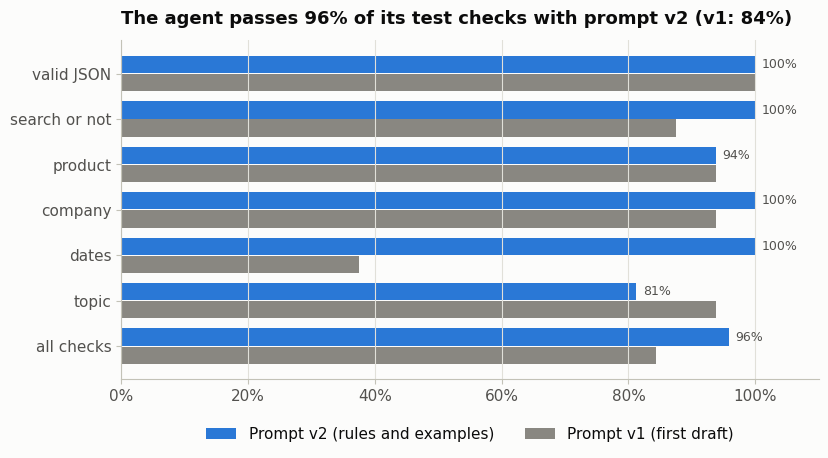

In [40]:
def week_of(day):
    start = pd.Timestamp(day)
    return start, start + pd.Timedelta(days=6)


def month_of(year, month):
    start = pd.Timestamp(year=year, month=month, day=1)
    return start, start + pd.offsets.MonthEnd(0)


ranked_alarms = alarm_review.sort_values("times normal", ascending=False)
topic_a = int(ranked_alarms.iloc[0]["topic"]) if len(ranked_alarms) else int(df["topic"].mode()[0])
week_a = ranked_alarms.iloc[0]["week"] if len(ranked_alarms) else pd.Timestamp("2025-01-13")
topic_b = next(int(t) for t in df["topic"].value_counts().index if t != topic_a)

AGENT_TESTS = [
    ("Hello! What can you do?", False, None, None, None, None),
    ("Thanks, that was helpful.", False, None, None, None, None),
    ("Why were Capital One customers complaining in the week of 13 January?", True, None,
     "CAPITAL ONE FINANCIAL CORPORATION", week_of("2025-01-13"), None),
    ("What did Cash App users report in January 2025?", True, None, "Block, Inc.", month_of(2025, 1), None),
    ("What problems did mortgage customers have in March?", True, PRODUCTS[3], None, month_of(2025, 3), None),
    ("Show me complaints about Zelle from the week of 6 October.", True, None, "Early Warning Services, LLC",
     week_of("2025-10-06"), None),
    ("What are people saying about overdraft fees at Navy Federal?", True, None, "NAVY FEDERAL CREDIT UNION", None, None),
    ("Which vehicle loan complaints mention repossession in June?", True, PRODUCTS[4], None, month_of(2025, 6), None),
    ("What did credit card customers complain about in the week of 17 November?", True, PRODUCTS[1], None,
     week_of("2025-11-17"), None),
    ("What did customers say about Wells Fargo in 2023?", True, None, "WELLS FARGO & COMPANY",
     (pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31")), None),
    (f"Why did complaints about {topic_names[topic_a].lower()} jump in the week of {week_a:%d %B}?", True, None, None,
     week_of(week_a), topic_a),
    (f"What are customers saying about {topic_names[topic_b].lower()}?", True, None, None, None, topic_b),
    ("Were there complaints about Chime disputes in early October?", True, None, "Chime Financial Inc",
     (pd.Timestamp("2025-10-01"), pd.Timestamp("2025-10-10")), None),
    ("What happened with money transfer complaints between 13 and 26 January?", True, PRODUCTS[2], None,
     (pd.Timestamp("2025-01-13"), pd.Timestamp("2025-01-26")), None),
    ("How did Bank of America customers describe checking account problems in April?", True, PRODUCTS[0],
     "BANK OF AMERICA, NATIONAL ASSOCIATION", month_of(2025, 4), None),
    ("Give me complaints about PayPal from the week of 3 March.", True, None, "Paypal Holdings, Inc",
     week_of("2025-03-03"), None),
]
CHECKS = ["valid JSON", "search or not", "product", "company", "dates", "topic"]


def dates_ok(decision, expected):
    if expected is None:
        return decision["date_from"] is None and decision["date_to"] is None
    if decision["date_from"] is None or decision["date_to"] is None:
        return False
    slack = pd.Timedelta(days=3)
    return abs(decision["date_from"] - expected[0]) <= slack and abs(decision["date_to"] - expected[1]) <= slack


def run_checks(decision, case):
    _, retrieve, product, company, dates, topic = case
    return {
        "valid JSON": decision["valid_json"],
        "search or not": decision["retrieve"] == retrieve,
        "product": decision["product"] == product,
        "company": decision["company"] is None if company is None else company in resolve_companies(decision["company"]),
        "dates": dates_ok(decision, dates),
        "topic": decision["topic"] == topic,
    }


AGENT_V1 = AGENT_V2 = None
agent_results = None
if RUN_QWEN:
    rows = []
    start = time.time()
    for version, prompt in [("v1", AGENT_PROMPT_V1), ("v2", AGENT_PROMPT_V2)]:
        for n, case in enumerate(AGENT_TESTS):
            decision = agent_decide(case[0], prompt)
            rows.append({"prompt": version, "question": n, "text": case[0], **run_checks(decision, case),
                         "reply": decision["reply"]})
    agent_results = pd.DataFrame(rows)
    pass_rates = agent_results.groupby("prompt")[CHECKS].mean().T
    pass_rates.loc["all checks"] = pass_rates.mean()
    AGENT_V1, AGENT_V2 = pass_rates.loc["all checks", "v1"], pass_rates.loc["all checks", "v2"]
    print(f"{len(agent_results)} agent answers in {time.time() - start:.0f} s")
    display(pass_rates.style.format("{:.0%}"))

    v2 = agent_results[agent_results["prompt"] == "v2"].copy()
    v2["failed checks"] = v2[CHECKS].apply(lambda r: ", ".join(c for c in CHECKS if not r[c]), axis=1)
    v2_failed = v2[v2["failed checks"] != ""]
    print(f"Prompt v2 missed at least one check on {len(v2_failed)} of {len(AGENT_TESTS)} questions")
    if len(v2_failed):
        display(v2_failed[["text", "failed checks", "reply"]].assign(reply=v2_failed["reply"].str.slice(0, 220)))

    fig, ax = plt.subplots(figsize=(9, 4.4))
    y = np.arange(len(pass_rates))
    ax.barh(y - 0.2, pass_rates["v2"], height=0.38, color=SERIES[0], label="Prompt v2 (rules and examples)")
    ax.barh(y + 0.2, pass_rates["v1"], height=0.38, color=MUTED, label="Prompt v1 (first draft)")
    for yy, value in zip(y, pass_rates["v2"]):
        ax.text(value + 0.01, yy - 0.2, f"{value:.0%}", va="center", color=INK_2, fontsize=9)
    ax.set_yticks(y, pass_rates.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.1)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
    ax.set_title(f"The agent passes {AGENT_V2:.0%} of its test checks with prompt v2 (v1: {AGENT_V1:.0%})")
    save_fig(fig, "fig12_agent_test_suite")
else:
    print("Agent tests skipped: Qwen3-4B needs a GPU runtime (RUN_QWEN = False)")

### 8.4 Filtered search and the brief

The search works like Assignment 3's `retrieve()`. The agent's filters select the allowed complaints; FAISS (with `IDSelectorBatch`) and BM25 each propose candidates from those complaints only; copies of the same template are kept once; and the cross-encoder re-ranks the candidates against the question and the agent's keyword query, keeping the better score.

**When the answer is "I don't know based on the complaints".** If no complaint matches the filters (for example a question about 2023), there is nothing to answer from. If the question sets no filters at all, Assignment 3's relevance threshold decides: the best candidate must score at least −3. We checked this threshold on real complaints before using it: the re-ranker scores a question that names the right company or problem above 0 and an unrelated question around −11, but it also scores open questions such as "what were Chime customers complaining about?" around −8 even on the right complaints. So when filters are set, the complaints that match them are the answer, and the threshold is not applied.

**Brief v1 and brief v2.** Our first full run showed three problems with the first brief (v1). The judge and the human check found them:

| Problem in brief v1 | Example from the first run | Change in brief v2 |
|---|---|---|
| The biggest group was missed | The 13 Jan "Late payment fees" alarm was 84% Navy Federal<br>overdraft letters, but the brief named other banks | The 3 largest groups of copies that match the filters<br>(each at least 2% of them) are always shown to the writer |
| The Scale line was wrong | "Scale: 1, 1, 1, 1", or "2 times" when every complaint<br>was filed once | Python counts the complaints and copies in the database<br>and writes the Scale line; the model writes the other lines |
| Template blanks read as facts | A blank such as "[describe the specific deceptive practice,<br>e.g. unauthorized charges]" was reported as a customer's words | Blanks in square brackets are removed before the model<br>reads the complaint |

**A prompt lesson.** In our first run of brief v2, its prompt also reworded the three lines (for example "starting with the texts filed most often"). Qwen3-4B then copied those instructions word for word into 8 of the 21 briefs, and the judge scored v2 below v1 (3.05 against 3.71), even though v2 named the company behind the surge more often (94% against 82%). Looking back, v1 had done the same in 5 of its 17 briefs written without filters, always when the complaints were mostly copied template letters, which v2 now puts first. So two changes:

- The v2 prompt keeps v1's wording for its three lines and adds only one sentence: a text filed many times stands for many customers, so describe it first.
- A safety net for both versions: a draft that repeats a line of the instructions is sent back to the model once, with a short correction. Section 8.5 counts how often this happens.

As in Assignment 4, even a small change to a prompt needs the whole test suite again.

Both versions use the same filters and the same "I don't know" rule, and both prompts allow only facts from the numbered complaints and no advice. Both are kept and scored with the same tests in 8.5, as with the agent prompts above and the v1 and v2 prompts of Assignment 4. Brief v2 was designed after reading the v1 briefs of these same alarms, so its scores here are development results: a pilot has to confirm them on new weeks.

In [41]:
bm25_all = BM25Okapi(df["tokens"].tolist())
RELEVANCE_THRESHOLD = -3.0
NO_ANSWER = "I don't know based on the complaints."
NO_FILTERS = {"date_from": None, "date_to": None, "product": None, "company": None, "topic": None}
GROUP_OF_ROW = df["group"].to_numpy()
BIG_GROUP_SLOTS = 3
BIG_GROUP_SHARE = 0.02
BIG_GROUP_MIN = max(3, round(10 * SCALE))
PLACEHOLDER = re.compile(r"\[[^\]]*(?:\b(?:describe|insert|enter|specify|explain|your)\b|e\.g\.)[^\]]*\]",
                         re.IGNORECASE)


def allowed_rows(filters):
    mask = np.ones(len(df), dtype=bool)
    if filters["date_from"] is not None:
        mask &= (df["date_received"] >= filters["date_from"]).to_numpy()
    if filters["date_to"] is not None:
        mask &= (df["date_received"] <= filters["date_to"]).to_numpy()
    if filters["product"] is not None:
        mask &= (df["product"] == filters["product"]).to_numpy()
    if filters["company"] is not None:
        mask &= df["company"].isin(resolve_companies(filters["company"])).to_numpy()
    if filters["topic"] is not None:
        mask &= (df["topic"] == filters["topic"]).to_numpy()
    return np.where(mask)[0].astype("int64")


def group_counts(allowed):
    return pd.Series(GROUP_OF_ROW[allowed]).value_counts()


def big_groups(allowed):
    counts = group_counts(allowed)
    counts = counts[counts >= max(BIG_GROUP_MIN, BIG_GROUP_SHARE * len(allowed))]
    return [int(allowed[np.argmax(GROUP_OF_ROW[allowed] == g)]) for g in counts.index[:BIG_GROUP_SLOTS]]


def search_complaints(question, search_query, allowed, top_k=6, n_candidates=30, keep_big_groups=False):
    if len(allowed) == 0:
        return []
    selector = faiss.IDSelectorBatch(len(allowed), faiss.swig_ptr(allowed))
    candidates = []
    for query in dict.fromkeys(q for q in (question, search_query) if q):
        vector = embedder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
        _, ids = index_all.search(vector, min(n_candidates, len(allowed)), params=faiss.SearchParameters(sel=selector))
        candidates += [int(i) for i in ids[0] if i != -1]
        scores = bm25_all.get_scores(list(bigram[tokenize(clean_text(query))]))[allowed]
        candidates += [int(allowed[i]) for i in np.argsort(-scores)[:n_candidates] if scores[i] > 0]
    must = big_groups(allowed) if keep_big_groups else []
    unique_hits, seen = [], set()
    for i in dict.fromkeys(must + candidates):
        if GROUP_OF_ROW[i] not in seen:
            seen.add(GROUP_OF_ROW[i])
            unique_hits.append(i)
    if not unique_hits:
        return []
    texts = [" ".join(df.at[i, "text"].split()[:200]) for i in unique_hits]
    relevance = reranker.predict([(question, text) for text in texts])
    if search_query and search_query != question:
        relevance = np.maximum(relevance, reranker.predict([(search_query, text) for text in texts]))
    copies = group_counts(allowed)
    order = list(range(len(must))) + [j for j in np.argsort(-relevance) if j >= len(must)]
    return [{"row": unique_hits[j], "score": float(relevance[j]), "copies": int(copies[GROUP_OF_ROW[unique_hits[j]]]),
             "big group": j < len(must)} for j in order[:top_k]]


BRIEF_PROMPT_V1 = """You help a bank's complaints manager understand a group of customer complaints.
Use ONLY the numbered complaints below. Each one shows its company, its date, its product and how many times
the same text was filed in the period searched.
Write exactly these four lines and nothing else:
What customers report: the main problem in one or two sentences, citing complaints like [1] or [3].
Who: the companies named in the complaints, the most frequent first.
When: the dates of the complaints.
Scale: how many times the main texts were filed, using the numbers shown.
Do not give advice. Do not add any fact that is not in the complaints.
Describe what these complaints say, even if they answer the question only in part.

Complaints:
{context}"""

BRIEF_PROMPT_V2 = """You help a bank's complaints manager understand a group of customer complaints.
Use ONLY the numbered complaints below. Each one shows its company, its date, its product and how many times
the same text was filed in the period searched. A text filed many times stands for many customers, so describe it first.
Write exactly these three lines and nothing else:
What customers report: the main problem in one or two sentences, citing complaints like [1] or [3].
Who: the companies named in the complaints, the most frequent first.
When: the dates of the complaints.
Do not give advice. Do not add any fact that is not in the complaints.
Describe what these complaints say, even if they answer the question only in part.

Complaints:
{context}"""

SMALL_TALK = ("You are the assistant of a bank's complaints team. Reply in one or two sentences. Do not state any "
              "facts. Invite the user to ask about the customer complaints of 2025.")
INSTRUCTION_PHRASES = ["in one or two sentences", "citing complaints like", "the most frequent first",
                       "the dates of the complaints", "filed most often", "the most filings first"]
RETRY_NOTE = ("You repeated the instructions instead of answering. Answer again with the same lines, filled with "
              "what the numbered complaints actually say.")


def repeats_prompt(text):
    return any(phrase in text.lower() for phrase in INSTRUCTION_PHRASES)


def context_parts(hits, remove_blanks=False):
    parts = []
    for n, h in enumerate(hits, start=1):
        row = h["row"]
        text = PLACEHOLDER.sub(" ", df.at[row, "text"]) if remove_blanks else df.at[row, "text"]
        parts.append(f"[{n}] {df.at[row, 'company']} | {df.at[row, 'date_received']:%d %b %Y} | "
                     f"{SHORT[df.at[row, 'product']]} | filed {h['copies']} time{'s' if h['copies'] > 1 else ''}\n"
                     + " ".join(text.split()[:150]))
    return parts


def scale_line(allowed, filtered):
    if not filtered:
        return f"Scale: no filters were set, so all {len(df):,} complaints were searched."
    counts = group_counts(allowed)
    shared = int(counts[counts > 1].sum())
    line = f"Scale: {len(allowed):,} complaint{'s' if len(allowed) > 1 else ''} match the filters"
    if shared:
        line += (f"; {shared / len(allowed):.0%} of them share their text with another complaint, "
                 f"and the largest group was filed {int(counts.iloc[0]):,} times")
    return line + "."


def has_filters(filters):
    return any(filters[key] is not None for key in NO_FILTERS)


def run_explain(question, use_filters=True, decision=None, check_relevance=True, version=2):
    decision = decision or agent_decide(question)
    result = {"question": question, "decision": decision, "version": version, "hits": [], "parts": [],
              "scale": None, "written": NO_ANSWER, "answer": NO_ANSWER, "retried": False}
    if not decision["retrieve"]:
        result["written"] = result["answer"] = generate(
            [{"role": "system", "content": SMALL_TALK}, {"role": "user", "content": question}], max_new_tokens=60)
        return result
    filters = decision if use_filters else NO_FILTERS
    filtered = has_filters(filters)
    allowed = allowed_rows(filters)
    hits = search_complaints(question, decision["search_query"], allowed, keep_big_groups=(version == 2 and filtered))
    needs_threshold = check_relevance and not filtered
    if hits and (not needs_threshold or max(h["score"] for h in hits) >= RELEVANCE_THRESHOLD):
        result["hits"] = hits
        result["parts"] = context_parts(hits, remove_blanks=(version == 2))
        prompt = BRIEF_PROMPT_V2 if version == 2 else BRIEF_PROMPT_V1
        messages = [{"role": "system", "content": prompt.format(context="\n\n".join(result["parts"]))},
                    {"role": "user", "content": question}]
        written = generate(messages, max_new_tokens=250)
        result["retried"] = repeats_prompt(written)
        if result["retried"]:
            written = generate(messages + [{"role": "assistant", "content": written},
                                           {"role": "user", "content": RETRY_NOTE}], max_new_tokens=250)
        if version == 2:
            written = "\n".join(line for line in written.splitlines() if not re.match(r"\W*scale\b", line, re.IGNORECASE))
            result["scale"] = scale_line(allowed, filtered)
        result["written"] = written.strip()
        result["answer"] = result["written"] + (f"\n{result['scale']}" if result["scale"] else "")
    return result


def describe_filters(decision):
    parts = []
    if decision["date_from"] is not None or decision["date_to"] is not None:
        start = f"{decision['date_from']:%d %b %Y}" if decision["date_from"] is not None else "any date"
        end = f"{decision['date_to']:%d %b %Y}" if decision["date_to"] is not None else "any date"
        parts.append(f"dates {start} to {end}")
    if decision["product"] is not None:
        parts.append(f"product {SHORT[decision['product']]}")
    if decision["company"] is not None:
        parts.append(f"company {decision['company']}")
    if decision["topic"] is not None:
        parts.append(f"topic {topic_names[decision['topic']]}")
    return ", ".join(parts) or "no filters"


def show_answer(result):
    decision = result["decision"]
    text = (f"**Question:** {result['question']}\n\n"
            f"**Agent:** search = {decision['retrieve']}, query = \"{decision['search_query']}\", "
            f"{describe_filters(decision)}\n\n" + result["answer"].replace("\n", "\n\n"))
    if result["hits"]:
        text += "\n\n**Sources:** " + ", ".join(f"[{n}] complaint {df.at[h['row'], 'complaint_id']}"
                                               for n, h in enumerate(result["hits"], start=1))
    display(Markdown(text.replace("$", "USD ")))

In [42]:
DEMO_QUESTIONS = [
    "What were Capital One customers complaining about in the week of 13 January 2025?",
    "Why did money transfer complaints go up in the week of 6 October 2025?",
    "What did customers say about Wells Fargo in 2023?",
    "Hello! What can you help me with?",
]
if RUN_QWEN:
    for question in DEMO_QUESTIONS:
        show_answer(run_explain(question))
else:
    print("Explain demo skipped: Qwen3-4B needs a GPU runtime (RUN_QWEN = False)")

**Question:** What were Capital One customers complaining about in the week of 13 January 2025?

**Agent:** search = True, query = "Capital One complaints", dates 13 Jan 2025 to 19 Jan 2025, company Capital One

What customers report: customers complain about issues with direct deposit failures and deceptive practices regarding high yield savings accounts.  

Who: CAPITAL ONE FINANCIAL CORPORATION  

When: 17 Jan 2025

Scale: 1,191 complaints match the filters; 38% of them share their text with another complaint, and the largest group was filed 374 times.

**Sources:** [1] complaint 11585572, [2] complaint 11558104, [3] complaint 11666772, [4] complaint 11663268, [5] complaint 11559679, [6] complaint 11559357

**Question:** Why did money transfer complaints go up in the week of 6 October 2025?

**Agent:** search = True, query = "money transfer complaints increased", dates 06 Oct 2025 to 12 Oct 2025, product Money transfer

What customers report: customers complain about issues with money transfer platforms like Zelle, Chime, and Cash App, including disputes, lack of accountability, and failure to recover lost funds [1], [2], [5].  

Who: Early Warning Services, LLC, Chime Financial Inc, Block, Inc.  

When: 06 Oct 2025.

Scale: 390 complaints match the filters; 61% of them share their text with another complaint, and the largest group was filed 134 times.

**Sources:** [1] complaint 16371143, [2] complaint 16371368, [3] complaint 16386211, [4] complaint 16447585, [5] complaint 16387910, [6] complaint 16403149

**Question:** What did customers say about Wells Fargo in 2023?

**Agent:** search = True, query = "Wells Fargo customer complaints", dates 01 Jan 2023 to 31 Dec 2023, company Wells Fargo

I don't know based on the complaints.

**Question:** Hello! What can you help me with?

**Agent:** search = False, query = "", no filters

I'm here to help with any questions you have about customer complaints. Would you like to know more about the customer complaints of 2025?

### 8.5 Does it explain real surges?

On the dashboard a manager clicks an alarm, so the alarm itself gives the filters: its topic and its week. The question is *"What were customers complaining about under the topic [topic] in the week of [date]?"*, and the topic's top words are the search query. Each alarm is answered three times: brief v2 with the alarm's filters, brief v1 with the same filters (to see what v2 changes), and brief v2 with no filters at all, the whole year (to see what the filters add, as we did with the source and date filters in Assignment 3). The relevance threshold is skipped in all three, because the alarm already says which complaints need explaining. Free-text questions go through the agent, as in the demo above and the event checks below.

Two automatic checks use facts from the complaint records that the model is never given as labels:

- **Right company:** the company with the most complaints in that topic and week must appear in the lines the model wrote.
- **Right week:** the share of the brief's sources that come from the alarm week.

17 alarms, 3 briefs each, in 330 s


,names main company,sources from alarm week,answered,first draft repeated the prompt,final brief repeats the prompt
mode,,,,,
v2 with filters,100%,100%,100%,6%,6%
v2 no filters,41%,7%,100%,0%,0%
v1 with filters,82%,100%,100%,0%,0%


,week,topic name,main company,named by brief v1,named by brief v2
0,13 Jan 2025,Late payment fees,NAVY FEDERAL CREDIT UNION,False,True
1,13 Jan 2025,Deceptive practices,"Block, Inc.",True,True
2,13 Jan 2025,Payment processing issues,"Early Warning Services, LLC",True,True
3,13 Jan 2025,Account access issues,CAPITAL ONE FINANCIAL CORPORATION,True,True
4,13 Jan 2025,Wallet transaction failures,"Early Warning Services, LLC",True,True
5,20 Jan 2025,Late payment fees,NAVY FEDERAL CREDIT UNION,False,True
6,20 Jan 2025,Deceptive practices,"Block, Inc.",True,True
7,20 Jan 2025,Wallet transaction failures,"Early Warning Services, LLC",True,True
8,27 Jan 2025,Late payment fees,NAVY FEDERAL CREDIT UNION,False,True
9,27 Jan 2025,Deceptive practices,"Block, Inc.",True,True


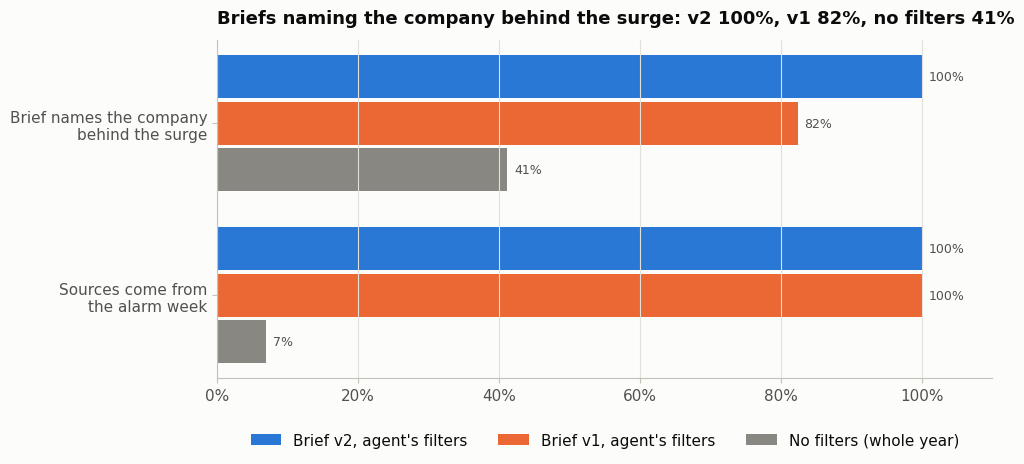

In [43]:
MAX_ALARM_BRIEFS = 12 if QUICK_RUN else 30
BRAND_KEYS = {"Block, Inc.": ["cash app", "cashapp", "block"], "Early Warning Services, LLC": ["zelle", "early warning"],
              "JPMORGAN CHASE & CO.": ["chase", "jpmorgan"], "CITIBANK, N.A.": ["citi", "citibank"],
              "U.S. BANCORP": ["u.s. bank", "us bank", "u.s. bancorp"],
              "UNITED SERVICES AUTOMOBILE ASSOCIATION": ["usaa", "united services"]}
BRIEF_RUNS = [("v2 with filters", 2, True), ("v2 no filters", 2, False), ("v1 with filters", 1, True)]


def company_keys(company):
    words = name_words(company)
    return BRAND_KEYS.get(company) or ([words[0]] if words else [company.lower()])


def mentions(text, keys):
    text = text.lower()
    return any(re.search(r"\b" + re.escape(k) + r"\b", text) for k in keys)


surge_rows = []
if RUN_QWEN and len(alarm_review):
    todo = (alarm_review.sort_values("times normal", ascending=False).head(MAX_ALARM_BRIEFS)
            .sort_values(["week", "topic"]))
    start = time.time()
    for _, alarm in todo.iterrows():
        question = (f"What were customers complaining about under the topic '{alarm['topic name']}' "
                    f"in the week of {alarm['week']:%d %B %Y}?")
        decision = {"retrieve": True, "search_query": " ".join(top_words[alarm["topic"]][:8]),
                    "date_from": alarm["week"], "date_to": alarm["week"] + pd.Timedelta(days=6), "product": None,
                    "company": None, "topic": alarm["topic"], "valid_json": True, "reply": ""}
        for mode, version, use_filters in BRIEF_RUNS:
            result = run_explain(question, use_filters, decision, check_relevance=False, version=version)
            hit_rows = [h["row"] for h in result["hits"]]
            surge_rows.append({
                "week": alarm["week"], "topic name": alarm["topic name"], "main company": alarm["main company"],
                "mode": mode, "question": question, "filters": describe_filters(decision),
                "answer": result["answer"], "scale": result["scale"], "parts": result["parts"],
                "names main company": mentions(result["written"], company_keys(alarm["main company"])),
                "sources from alarm week": float(np.mean([df.at[r, "week"] == alarm["week"] for r in hit_rows]))
                                           if hit_rows else 0.0,
                "answered": bool(result["hits"]) and NO_ANSWER.lower() not in result["written"].lower(),
                "first draft repeated the prompt": result["retried"],
                "final brief repeats the prompt": repeats_prompt(result["written"]),
            })
    print(f"{len(todo)} alarms, {len(BRIEF_RUNS)} briefs each, in {time.time() - start:.0f} s")
surge = pd.DataFrame(surge_rows)

COMPANY_HIT_FILTERED = COMPANY_HIT_UNFILTERED = COMPANY_HIT_V1 = WEEK_SHARE_FILTERED = WEEK_SHARE_UNFILTERED = None
if len(surge):
    surge_summary = (surge.groupby("mode")[["names main company", "sources from alarm week", "answered",
                                            "first draft repeated the prompt", "final brief repeats the prompt"]].mean()
                     .reindex([mode for mode, _, _ in BRIEF_RUNS]))
    COMPANY_HIT_FILTERED, COMPANY_HIT_UNFILTERED, COMPANY_HIT_V1 = surge_summary["names main company"]
    WEEK_SHARE_FILTERED, WEEK_SHARE_UNFILTERED = surge_summary["sources from alarm week"].iloc[:2]
    display(surge_summary.style.format("{:.0%}"))
    v2_rows = surge[surge["mode"] == "v2 with filters"].reset_index(drop=True)
    v1_rows = surge[surge["mode"] == "v1 with filters"].reset_index(drop=True)
    display(pd.DataFrame({"week": v2_rows["week"].dt.strftime("%d %b %Y"), "topic name": v2_rows["topic name"],
                          "main company": v2_rows["main company"], "named by brief v1": v1_rows["names main company"],
                          "named by brief v2": v2_rows["names main company"]}))

    fig, ax = plt.subplots(figsize=(10, 4.4))
    metrics = ["names main company", "sources from alarm week"]
    y = np.arange(len(metrics))
    bars = [("v2 with filters", SERIES[0], "Brief v2, agent's filters"),
            ("v1 with filters", SERIES[1], "Brief v1, agent's filters"),
            ("v2 no filters", MUTED, "No filters (whole year)")]
    for k, (mode, color, label) in enumerate(bars):
        offset = (k - 1) * 0.27
        values = surge_summary.loc[mode, metrics].to_numpy(dtype=float)
        ax.barh(y + offset, values, height=0.25, color=color, label=label)
        for yy, value in zip(y, values):
            ax.text(value + 0.01, yy + offset, f"{value:.0%}", va="center", color=INK_2, fontsize=9)
    ax.set_yticks(y, ["Brief names the company\nbehind the surge", "Sources come from\nthe alarm week"])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.1)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
    ax.set_title(f"Briefs naming the company behind the surge: v2 {COMPANY_HIT_FILTERED:.0%}, "
                 f"v1 {COMPANY_HIT_V1:.0%}, no filters {COMPANY_HIT_UNFILTERED:.0%}")
    save_fig(fig, "fig13_briefs_with_and_without_filters")
else:
    print("Surge briefs skipped (needs RUN_QWEN = True and at least one alarm)")

**The January events.** For each dated event, a manager asks an open question that names the company and the week but not the cause. The brief passes if the lines written by the model name the cause (keywords checked automatically; the counted Scale line is left out). Both brief versions are checked. The October copy-paste campaign from section 7 is checked the same way, as an extra row.

In [44]:
EVENT_CHECKS = [
    ("January event", "Outage at FIS delays Capital One deposits (15–19 Jan)",
     "What were Capital One customers complaining about in the week of 13 January 2025?", ["deposit", "deposits"]),
    ("January event", "CFPB sues Capital One over 360 Savings (14 Jan)",
     "What did Capital One savings account customers report in the week of 13 January 2025?",
     ["360", "interest", "rate", "rates"]),
    ("January event", "CFPB orders Block (Cash App) to fix fraud handling (16 Jan)",
     "What were Cash App customers complaining about in the week of 13 January 2025?",
     ["fraud", "unauthorized", "dispute", "disputes", "customer service", "support", "refund"]),
    ("October campaign", "Copy-paste dispute letter against Zelle and Chime",
     "What were Chime customers complaining about in the week of 6 October 2025?", ["dispute", "disputes", "lawsuit"]),
]

EVENTS_FOUND = EVENTS_FOUND_UNFILTERED = EVENTS_FOUND_V1 = None
event_results = []
if RUN_QWEN:
    for kind, event, question, keywords in EVENT_CHECKS:
        decision = agent_decide(question)
        row = {"kind": kind, "event": event, "question": question, "filters": describe_filters(decision)}
        for mode, version, use_filters in BRIEF_RUNS:
            result = run_explain(question, use_filters, decision, version=version)
            row[f"found ({mode})"] = mentions(result["written"], keywords)
            row[f"brief ({mode})"] = result["answer"]
            row[f"parts ({mode})"] = result["parts"]
            row[f"scale ({mode})"] = result["scale"]
        event_results.append(row)
    event_table = pd.DataFrame(event_results)
    january = event_table["kind"] == "January event"
    EVENTS_FOUND, EVENTS_FOUND_UNFILTERED, EVENTS_FOUND_V1 = [int(event_table.loc[january, f"found ({mode})"].sum())
                                                              for mode, _, _ in BRIEF_RUNS]
    display(event_table[["kind", "event", "filters"] + [f"found ({mode})" for mode, _, _ in BRIEF_RUNS]])
    print(f"January events named in the briefs: brief v2 {EVENTS_FOUND} of 3, brief v1 {EVENTS_FOUND_V1} of 3, "
          f"no filters {EVENTS_FOUND_UNFILTERED} of 3")
    for row in event_results:
        display(Markdown(f"**{row['event']}**\n\n*{row['question']}*\n\n"
                         + "**Brief v1:**\n\n" + row["brief (v1 with filters)"].replace("\n", "\n\n").replace("$", "USD ")
                         + "\n\n**Brief v2:**\n\n" + row["brief (v2 with filters)"].replace("\n", "\n\n").replace("$", "USD ")))
else:
    print("Event checks skipped: Qwen3-4B needs a GPU runtime (RUN_QWEN = False)")

,kind,event,filters,found (v2 with filters),found (v2 no filters),found (v1 with filters)
0,January event,Outage at FIS delays Capital One deposits (15–19 Jan),"dates 13 Jan 2025 to 19 Jan 2025, company Capital One",True,False,True
1,January event,CFPB sues Capital One over 360 Savings (14 Jan),"dates 13 Jan 2025 to 19 Jan 2025, product Checking/savings, company Capital One",False,True,False
2,January event,CFPB orders Block (Cash App) to fix fraud handling (16 Jan),"dates 13 Jan 2025 to 19 Jan 2025, company Cash App",True,True,True
3,October campaign,Copy-paste dispute letter against Zelle and Chime,"dates 06 Oct 2025 to 12 Oct 2025, product Checking/savings, company Chime",True,False,True


January events named in the briefs: brief v2 2 of 3, brief v1 2 of 3, no filters 2 of 3


**Outage at FIS delays Capital One deposits (15–19 Jan)**

*What were Capital One customers complaining about in the week of 13 January 2025?*

**Brief v1:**

What customers report: customers reported deceptive practices by Capital One regarding high yield interest savings accounts and banking outages affecting direct deposits. [1], [3], [4], [6]  

Who: CAPITAL ONE FINANCIAL CORPORATION  

When: 17 Jan 2025, 18 Jan 2025  

Scale: the main texts were filed 1 time each.

**Brief v2:**

What customers report: customers complain about issues with direct deposit failures and deceptive practices regarding high yield savings accounts.  

Who: CAPITAL ONE FINANCIAL CORPORATION  

When: 17 Jan 2025

Scale: 1,191 complaints match the filters; 38% of them share their text with another complaint, and the largest group was filed 374 times.

**CFPB sues Capital One over 360 Savings (14 Jan)**

*What did Capital One savings account customers report in the week of 13 January 2025?*

**Brief v1:**

What customers report: [1], [2], [3], [5] report issues with delayed or missing direct deposits and technical problems with their Capital One accounts, causing financial difficulties.  

Who: CAPITAL ONE FINANCIAL CORPORATION  

When: 15 Jan 2025, 17 Jan 2025, 18 Jan 2025  

Scale: [1], [2], [3], [5] each filed 1 time.

**Brief v2:**

What customers report: customers reported issues with direct deposit delays and technical problems affecting access to funds, as noted in [1], [3], [4], and [5].  

Who: CAPITAL ONE FINANCIAL CORPORATION.  

When: 17 Jan 2025.

Scale: 1,109 complaints match the filters; 41% of them share their text with another complaint, and the largest group was filed 374 times.

**CFPB orders Block (Cash App) to fix fraud handling (16 Jan)**

*What were Cash App customers complaining about in the week of 13 January 2025?*

**Brief v1:**

What customers report: complaints about inadequate customer service and unfair practices by Cash App, specifically regarding failure to prevent and address fraud, leaving accounts vulnerable and unprotected.  

Who: Block, Inc. (Cash App)  

When: 17 Jan 2025  

Scale: the main text was filed 5649 times.

**Brief v2:**

What customers report: customers complained about inadequate customer service and unfair practices by Cash App, specifically regarding fraud prevention and dispute resolution.  

Who: Block, Inc.  

When: 16 Jan 2025, 17 Jan 2025.

Scale: 6,226 complaints match the filters; 92% of them share their text with another complaint, and the largest group was filed 5,649 times.

**Copy-paste dispute letter against Zelle and Chime**

*What were Chime customers complaining about in the week of 6 October 2025?*

**Brief v1:**

What customers report: customers report unauthorized debits, fraud impersonation calls, account closures, and dispute handling issues [1], [2], [3], [4].  

Who: Chime Financial Inc.  

When: 06 Oct 2025, 07 Oct 2025, 08 Oct 2025, 09 Oct 2025.  

Scale: the main texts were filed 1 time [1], 1 time [2], 1 time [3], 2 times [4].

**Brief v2:**

What customers report: unauthorized debits and failed refunds, fraud impersonation calls, account closures due to suspicious activity, and disputes over missing products and refunds.  

Who: Chime Financial Inc.  

When: 06 Oct 2025, 07 Oct 2025, 08 Oct 2025.

Scale: 34 complaints match the filters; 6% of them share their text with another complaint, and the largest group was filed 2 times.

### RAGAs and the LLM judge

As in Assignment 3, RAGAs scores **faithfulness** (is every statement in the brief backed by the complaints?) and **answer relevancy**, with `gpt-4o-mini` as the judge (Session 11). Every brief written with filters is scored, for both brief versions: one per alarm, plus the event questions. For brief v2, the database count behind the Scale line is given to RAGAs and to the judge as one more context, so that line can be checked too.

In [45]:
def with_scale(parts, scale):
    return list(parts) + ([scale] if isinstance(scale, str) else [])


def graded_briefs(mode):
    items = []
    if len(surge):
        for _, r in surge[(surge["mode"] == mode) & surge["answered"]].iterrows():
            items.append({"question": r["question"], "answer": r["answer"], "parts": with_scale(r["parts"], r["scale"])})
    for r in event_results:
        if r[f"brief ({mode})"] != NO_ANSWER:
            items.append({"question": r["question"], "answer": r[f"brief ({mode})"],
                          "parts": with_scale(r[f"parts ({mode})"], r[f"scale ({mode})"])})
    return items


graded = graded_briefs("v2 with filters")
graded_v1 = graded_briefs("v1 with filters")

FAITHFULNESS = RELEVANCY = FAITHFULNESS_V1 = RELEVANCY_V1 = None
ragas_table = ragas_table_v1 = None
if graded and RUN_OPENAI:
    from ragas import evaluate, EvaluationDataset, RunConfig
    from ragas.metrics import faithfulness, answer_relevancy
    from ragas.llms import LangchainLLMWrapper
    from ragas.embeddings import LangchainEmbeddingsWrapper
    from langchain_core.embeddings import Embeddings
    from langchain_openai import ChatOpenAI

    judge = LangchainLLMWrapper(ChatOpenAI(model=JUDGE_MODEL, temperature=0))

    class MpnetEmbeddings(Embeddings):
        def embed_documents(self, texts):
            return embedder.encode(texts, normalize_embeddings=True).tolist()

        def embed_query(self, text):
            return embedder.encode(text, normalize_embeddings=True).tolist()

    def ragas_scores(items):
        dataset = EvaluationDataset.from_list([
            {"user_input": g["question"], "response": g["answer"], "retrieved_contexts": g["parts"]} for g in items])
        scores = evaluate(dataset, metrics=[faithfulness, answer_relevancy], llm=judge,
                          embeddings=LangchainEmbeddingsWrapper(MpnetEmbeddings()),
                          run_config=RunConfig(max_workers=2, timeout=600, max_retries=5, max_wait=60))
        table = scores.to_pandas()
        table.insert(0, "question", [g["question"] for g in items])
        return table

    ragas_table = ragas_scores(graded)
    FAITHFULNESS, RELEVANCY = ragas_table["faithfulness"].mean(), ragas_table["answer_relevancy"].mean()
    if graded_v1:
        ragas_table_v1 = ragas_scores(graded_v1)
        FAITHFULNESS_V1, RELEVANCY_V1 = ragas_table_v1["faithfulness"].mean(), ragas_table_v1["answer_relevancy"].mean()
    ragas_compare = pd.DataFrame({"briefs": [len(graded_v1), len(graded)],
                                  "faithfulness": [FAITHFULNESS_V1, FAITHFULNESS],
                                  "answer relevancy": [RELEVANCY_V1, RELEVANCY]}, index=["brief v1", "brief v2"])
    print(f"RAGAs over {len(graded)} briefs (v2): faithfulness {FAITHFULNESS:.2f}, answer relevancy {RELEVANCY:.2f}")
    display(ragas_compare.style.format({"faithfulness": "{:.2f}", "answer relevancy": "{:.2f}"}, na_rep="–"))
    display(ragas_table[["question", "faithfulness", "answer_relevancy"]]
            .style.format({"faithfulness": "{:.2f}", "answer_relevancy": "{:.2f}"}))
else:
    print("RAGAs skipped (needs briefs and RUN_OPENAI = True)")

Evaluating:   0%|          | 0/42 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/42 [00:00<?, ?it/s]

RAGAs over 21 briefs (v2): faithfulness 0.98, answer relevancy 0.61


,briefs,faithfulness,answer relevancy
brief v1,21,0.95,0.62
brief v2,21,0.98,0.61


,question,faithfulness,answer_relevancy
0,What were customers complaining about under the topic 'Late payment fees' in the week of 13 January 2025?,1.00,0.74
1,What were customers complaining about under the topic 'Deceptive practices' in the week of 13 January 2025?,1.00,0.53
2,What were customers complaining about under the topic 'Payment processing issues' in the week of 13 January 2025?,1.00,0.64
3,What were customers complaining about under the topic 'Account access issues' in the week of 13 January 2025?,0.88,0.77
4,What were customers complaining about under the topic 'Wallet transaction failures' in the week of 13 January 2025?,1.00,0.66
5,What were customers complaining about under the topic 'Late payment fees' in the week of 20 January 2025?,1.00,0.78
6,What were customers complaining about under the topic 'Deceptive practices' in the week of 20 January 2025?,1.00,0.57
7,What were customers complaining about under the topic 'Wallet transaction failures' in the week of 20 January 2025?,1.00,0.55
8,What were customers complaining about under the topic 'Late payment fees' in the week of 27 January 2025?,1.00,0.62
9,What were customers complaining about under the topic 'Deceptive practices' in the week of 27 January 2025?,1.00,0.46


In [46]:
JUDGE_SYSTEM = """You review short briefs written for a bank's complaints manager about a group of complaints. Be strict.
You get the manager's question, the complaints the brief was written from, then the brief.
When the complaints end with a line that starts with "Scale:", that line is a count taken from the complaint
database: treat it as correct.
First list every statement in the brief that is not supported by the complaints.
Then score usefulness for the manager on this scale:
1 = wrong or misleading, 2 = vague or generic, 3 = correct but the manager still has to read the complaints,
4 = correct and specific: the manager understands what the complaints are about,
5 = correct, specific and complete: what happened, which companies, when and how many.
Return JSON with these keys:
"unsupported_statements": a list of strings (empty if none),
"usefulness": 1 to 5,
"reason": one short sentence."""


def judge_briefs(items):
    verdicts = []
    for n, g in enumerate(items):
        reply, _, _ = ask_openai(JUDGE_SYSTEM, f"QUESTION:\n{g['question']}\n\nCOMPLAINTS:\n" + "\n\n".join(g["parts"])
                                 + "\n\nBRIEF:\n" + g["answer"], max_tokens=400, json_mode=True)
        result = json.loads(reply)
        problems = result.get("unsupported_statements") or []
        verdicts.append({"brief": n, "question": g["question"], "usefulness": int(result.get("usefulness", 0)),
                         "unsupported statements": len(problems), "example": problems[0] if problems else "",
                         "reason": result.get("reason", "")})
    return pd.DataFrame(verdicts).set_index("brief")


JUDGE_MEAN = JUDGE_MEAN_V1 = UNSUPPORTED = UNSUPPORTED_V1 = None
judge_table = judge_table_v1 = None
if graded and RUN_OPENAI:
    judge_table = judge_briefs(graded)
    JUDGE_MEAN = judge_table["usefulness"].mean()
    UNSUPPORTED = int((judge_table["unsupported statements"] > 0).sum())
    if graded_v1:
        judge_table_v1 = judge_briefs(graded_v1)
        JUDGE_MEAN_V1 = judge_table_v1["usefulness"].mean()
        UNSUPPORTED_V1 = int((judge_table_v1["unsupported statements"] > 0).sum())
    judge_compare = pd.DataFrame({
        "briefs": [len(graded_v1), len(graded)],
        "mean usefulness (1 to 5)": [JUDGE_MEAN_V1, JUDGE_MEAN],
        "briefs with an unsupported statement": [UNSUPPORTED_V1, UNSUPPORTED]}, index=["brief v1", "brief v2"])
    display(judge_compare.style.format({"mean usefulness (1 to 5)": "{:.2f}"}, na_rep="–"))
    print(f"Brief v2: usefulness {JUDGE_MEAN:.2f} / 5 (range {judge_table['usefulness'].min()}–"
          f"{judge_table['usefulness'].max()}), briefs with unsupported statements: {UNSUPPORTED} of {len(judge_table)}")
    display(judge_table)
else:
    print("Judge skipped (needs briefs and RUN_OPENAI = True)")

,briefs,mean usefulness (1 to 5),briefs with an unsupported statement
brief v1,21,3.71,9
brief v2,21,4.52,4


Brief v2: usefulness 4.52 / 5 (range 3–5), briefs with unsupported statements: 4 of 21


,question,usefulness,unsupported statements,example,reason
brief,,,,,
0,What were customers complaining about under the topic 'Late payment fees' in the week of 13 January 2025?,5,0,,"The brief accurately summarizes the complaints, specifying the companies involved, the nature of the complaints, and the relevant dates."
1,What were customers complaining about under the topic 'Deceptive practices' in the week of 13 January 2025?,5,0,,"The brief accurately summarizes the complaints, specifying the companies, dates, and nature of the deceptive practices."
2,What were customers complaining about under the topic 'Payment processing issues' in the week of 13 January 2025?,5,0,,"The brief accurately summarizes the complaints, specifying the issues, companies involved, and dates."
3,What were customers complaining about under the topic 'Account access issues' in the week of 13 January 2025?,5,0,,"The brief accurately summarizes the complaints, specifying the issues, companies involved, and dates."
4,What were customers complaining about under the topic 'Wallet transaction failures' in the week of 13 January 2025?,5,0,,"The brief accurately summarizes the complaints, specifying the issues, companies involved, and relevant dates."
5,What were customers complaining about under the topic 'Late payment fees' in the week of 20 January 2025?,5,0,,"The brief accurately summarizes the complaints regarding late payment fees, specifying the companies involved and the relevant dates."
6,What were customers complaining about under the topic 'Deceptive practices' in the week of 20 January 2025?,3,2,customers complain about inadequate customer service,The brief is correct but lacks specific details from the complaints.
7,What were customers complaining about under the topic 'Wallet transaction failures' in the week of 20 January 2025?,5,0,,"The brief accurately summarizes the complaints, specifying the companies involved, the timeframe, and the nature of the issues."
8,What were customers complaining about under the topic 'Late payment fees' in the week of 27 January 2025?,3,2,customers complain about unfair overdraft fees,The brief contains correct information but lacks specificity regarding the complaints about late payment fees.


### Human spot-check of the judge

An LLM judge can be biased (Session 11, *"watch judge bias"*). Read briefs 0 to 4 below, with the first complaints they were written from, and give each your own usefulness score on the judge's scale:

1 = wrong or misleading · 2 = vague or generic · 3 = correct, but the manager still has to read the complaints · 4 = correct and specific · 5 = correct, specific and complete (what, who, when, how many)

Type them into `HUMAN_USEFULNESS`, for example `{0: 4, 1: 3, 2: 5, 3: 4, 4: 2}`, run that cell, then run the cells from section 10 onward so the scorecard and the findings use your scores.

In [47]:
for n, g in enumerate(graded[:5]):
    print(f"--- Brief {n}\nQUESTION: {g['question']}\n")
    print(g["answer"], "\n")
    for part in g["parts"]:
        print("   ", part[:700].replace("\n", " | "), "...")
    print()

--- Brief 0
QUESTION: What were customers complaining about under the topic 'Late payment fees' in the week of 13 January 2025?

What customers report: customers complained about being charged late fees despite having sufficient funds or making timely payments, with issues related to delayed posting of transactions and unfair fee assessments.  
Who: Navy Federal Credit Union, Capital One Financial Corporation, Bread Financial Holdings, Inc., Barclays Bank Delaware, Ally Financial Inc.  
When: 15 Jan 2025, 16 Jan 2025.
Scale: 1,427 complaints match the filters; 71% of them share their text with another complaint, and the largest group was filed 949 times. 

    [1] NAVY FEDERAL CREDIT UNION | 15 Jan 2025 | Checking/savings | filed 949 times | I am writing to file a complaint against Navy Federal Credit Union regarding multiple overdraft fees I have incurred. Despite having sufficient funds when transactions were authorized, I was charged fees due to lagged posting of charges and credits

In [53]:
HUMAN_USEFULNESS = {0: 1, 1: 3, 2: 4, 3: 4, 4: 5}
JUDGE_AGREEMENT = None
if HUMAN_USEFULNESS and judge_table is not None:
    compare = pd.DataFrame({"human": pd.Series(HUMAN_USEFULNESS), "judge": judge_table["usefulness"]}).dropna()
    compare["difference"] = compare["judge"] - compare["human"]
    JUDGE_AGREEMENT = (compare["difference"].abs() <= 1).mean()
    display(compare)
    print(f"Judge within 1 point of the human on {JUDGE_AGREEMENT:.0%} of briefs, "
          f"mean difference {compare['difference'].mean():+.2f}")
else:
    print("Human scores not entered yet")

,human,judge,difference
0,1.0,5,4.0
1,3.0,5,2.0
2,4.0,5,1.0
3,4.0,5,1.0
4,5.0,5,0.0


Judge within 1 point of the human on 60% of briefs, mean difference +1.60


## 9. Responsible AI

| Risk | What we did |
|---|---|
| Privacy | The CFPB removes personal details before publishing (XXXX).<br>In production the open Qwen3-4B model runs inside the bank, so<br>complaint text is not sent to an outside service. `gpt-4o-mini` is<br>only used here, on public CFPB text, to grade the results. |
| Unfair treatment | The payout model is checked for Older American and<br>Servicemember complaints (section 6) against the 5-point target. |
| Made-up answers | Briefs use only the retrieved complaints and cite them. Counts<br>come from the database, not the model, and template blanks<br>are removed. The assistant says "I don't know" when nothing<br>relevant is found. RAGAs, the judge and a person check for<br>unsupported statements. |
| Automation without oversight | Every output is a suggestion: an agent confirms the route and<br>reviews the risk, and a manager decides what an alarm means<br>and what to do about it. |
| Campaigns | A copy-paste campaign is still real customers using their rights.<br>Copies are grouped for one reviewed answer, never discarded. |
| Label quality | Products and issues are chosen by consumers, so some labels<br>are wrong. Scores are a fair estimate, not an exact one. |
| Regulation | Complaint handling is not a high-risk use under the EU AI Act;<br>it would need human oversight and logging, which this design<br>already has. |

## 10. Scorecard: targets against results

In [58]:
def verdict(ok):
    if isinstance(ok, str):
        return ok
    return "not measured yet" if ok is None else ("✅ met" if ok else "❌ not met")


def shown(value, spec):
    return "–" if value is None else format(value, spec)


TUNED_NMI = best_setting["agreement with CFPB issues (NMI)"]
hidden_text = "none"
if SHOWCASE_WEEK is not None:
    hidden_text = (f"{len(HIDDEN_FROM_COUNTS)} weeks; e.g. {SHOWCASE_WEEK:%d %b}: all complaints "
                   f"{lens.at[SHOWCASE_WEEK, 'all complaints']:.1f}×, one topic {lens.at[SHOWCASE_WEEK, 'busiest topic']:.0f}×")
scorecard = pd.DataFrame([
    ("Clean", "Copy pairs confirmed by a person", "–", "≥ 18 of 20",
     f"{HUMAN_CONFIRMED} of {len(human_check)}" if HUMAN_CONFIRMED is not None else "–",
     None if HUMAN_CONFIRMED is None else HUMAN_CONFIRMED >= 18),
    ("Route", "Accuracy on held-out complaints", f"Keyword rules {ACC_KW:.0%}", "≥ 80% and above keywords",
     f"{ACC_ROUTER:.0%} (macro-F1 {F1_ROUTER:.2f})", bool(ACC_ROUTER >= 0.8 and ACC_ROUTER > ACC_KW)),
    ("Prioritise", "Payouts caught in the riskiest 20%", "Random 20%", "≥ 40%",
     f"{CAUGHT_20:.0%}", bool(CAUGHT_20 >= 0.4)),
    ("Watch", "Topic coherence (c_v)", f"Untuned {UNTUNED_COHERENCE:.2f}", "≥ 0.40 and above untuned",
     f"{LDA_COHERENCE:.2f}", bool(LDA_COHERENCE >= 0.4 and LDA_COHERENCE > UNTUNED_COHERENCE)),
    ("Watch", "Agreement with CFPB issues (NMI)", f"Untuned {UNTUNED_NMI:.2f}", "no target (diagnostic)",
     f"{TUNED_NMI:.2f}", "ℹ️ diagnostic"),
    ("Watch", "Alarm within 7 days of the January events", "–", "yes", "yes" if ALARM_OK else "no", ALARM_OK),
    ("Watch", "Weeks that only the topic alarm catches", "Counting all complaints or per team",
     "no target (diagnostic)", hidden_text, "ℹ️ diagnostic"),
    ("Watch", "Alarms explained by a dated event or a copy campaign", "–", "no target (diagnostic)",
     f"{ALARMS_EXPLAINED} of {len(alarm_review)}", "ℹ️ diagnostic"),
    ("Explain", "Precision@5 (same issue), best search", f"BM25 {P5_BM25:.2f}", "above BM25",
     f"{P5_OURS:.2f} ({P5_BEST_NAME})", bool(P5_OURS > P5_BM25)),
    ("Explain", "Agent test checks passed", f"Prompt v1 {shown(AGENT_V1, '.0%')}", "≥ 90% and above v1",
     shown(AGENT_V2, ".0%"), None if AGENT_V2 is None else bool(AGENT_V2 >= 0.9 and AGENT_V2 > AGENT_V1)),
    ("Explain", "Surge briefs that name the company behind the surge",
     f"No filters {shown(COMPANY_HIT_UNFILTERED, '.0%')}; brief v1 {shown(COMPANY_HIT_V1, '.0%')}",
     "≥ 80% and above no filters", shown(COMPANY_HIT_FILTERED, ".0%"),
     None if COMPANY_HIT_FILTERED is None else bool(COMPANY_HIT_FILTERED >= 0.8
                                                     and COMPANY_HIT_FILTERED > COMPANY_HIT_UNFILTERED)),
    ("Explain", "January events named in that week's briefs",
     f"No filters {EVENTS_FOUND_UNFILTERED} of 3; brief v1 {EVENTS_FOUND_V1} of 3" if EVENTS_FOUND is not None else "–",
     "3 of 3", f"{EVENTS_FOUND} of 3" if EVENTS_FOUND is not None else "–",
     None if EVENTS_FOUND is None else EVENTS_FOUND == 3),
    ("Explain", "RAGAs faithfulness of the briefs", f"Brief v1 {shown(FAITHFULNESS_V1, '.2f')}", "≥ 0.80",
     shown(FAITHFULNESS, ".2f"), None if FAITHFULNESS is None else bool(FAITHFULNESS >= 0.8)),
    ("Explain", "RAGAs answer relevancy", f"Brief v1 {shown(RELEVANCY_V1, '.2f')}", "no target (diagnostic)",
     shown(RELEVANCY, ".2f"), "ℹ️ diagnostic"),
    ("Explain", "Judge usefulness of the briefs (1 to 5)", f"Brief v1 {shown(JUDGE_MEAN_V1, '.2f')}", "above brief v1",
     shown(JUDGE_MEAN, ".2f"), None if JUDGE_MEAN is None or JUDGE_MEAN_V1 is None else bool(JUDGE_MEAN > JUDGE_MEAN_V1)),
    ("Explain", "Briefs with a statement the judge found unsupported",
     f"Brief v1 {UNSUPPORTED_V1} of {len(judge_table_v1)}" if judge_table_v1 is not None else "–",
     "no target (diagnostic)", f"{UNSUPPORTED} of {len(judge_table)}" if judge_table is not None else "–",
     "ℹ️ diagnostic"),
    ("Explain", "Judge within 1 point of a person (5 briefs)", "–", "no target (diagnostic)",
     shown(JUDGE_AGREEMENT, ".0%"), "ℹ️ diagnostic"),
    ("Fairness", "Shortfall in payouts caught (tagged vs untagged)", "–", "≤ 5 points",
     f"{FAIRNESS_GAP * 100:.1f} points", bool(FAIRNESS_GAP <= 0.05)),
], columns=["stage", "metric", "baseline", "target", "result", "met"])
scorecard["met"] = scorecard["met"].map(verdict)
scorecard.to_csv(os.path.join(FIG_DIR, "scorecard.csv"), index=False)
display(scorecard.set_index("stage"))

,metric,baseline,target,result,met
stage,,,,,
Clean,Copy pairs confirmed by a person,–,≥ 18 of 20,19 of 20,✅ met
Route,Accuracy on held-out complaints,Keyword rules 71%,≥ 80% and above keywords,81% (macro-F1 0.82),✅ met
Prioritise,Payouts caught in the riskiest 20%,Random 20%,≥ 40%,52%,✅ met
Watch,Topic coherence (c_v),Untuned 0.48,≥ 0.40 and above untuned,0.54,✅ met
Watch,Agreement with CFPB issues (NMI),Untuned 0.23,no target (diagnostic),0.21,ℹ️ diagnostic
Watch,Alarm within 7 days of the January events,–,yes,yes,✅ met
Watch,Weeks that only the topic alarm catches,Counting all complaints or per team,no target (diagnostic),"3 weeks; e.g. 06 Oct: all complaints 1.1×, one topic 136×",ℹ️ diagnostic
Watch,Alarms explained by a dated event or a copy campaign,–,no target (diagnostic),16 of 17,ℹ️ diagnostic
Explain,"Precision@5 (same issue), best search",BM25 0.35,above BM25,0.41 (FAISS + routed-team filter),✅ met


## 11. Business impact (illustrative)

The value comes from three places:

1. **Less manual triage:** complaints that are routed correctly need no person to read them first.
2. **Payouts handled first:** reviewing the riskiest complaints first reaches most payouts early, so customers who are owed money get answered sooner.
3. **Problems found earlier:** section 1 shows what the complaint waves of 2025 were tied to: refunds, penalties and settlements from USD 95 million to USD 425 million. We do not claim this tool would have avoided those costs. A team that sees a surge and its cause in the same week can fix the process, refund customers and prepare its answer to the regulator sooner.

The first one can be sized for one large bank with the numbers below. **The minutes, the hourly cost and our price are assumptions to confirm with a bank**; the complaint volume and the accuracy come from the data.

In [59]:
COMPLAINTS_PER_YEAR = 11_910
MINUTES_TO_TRIAGE = 10
HOURLY_COST_USD = 45
PRICE_PER_COMPLAINT_USD = 1.0

routed_right = COMPLAINTS_PER_YEAR * ACC_ROUTER
hours_saved = routed_right * MINUTES_TO_TRIAGE / 60
triage_saving = hours_saved * HOURLY_COST_USD
yearly_price = COMPLAINTS_PER_YEAR * PRICE_PER_COMPLAINT_USD
impact = pd.DataFrame([
    ("Complaints with a written story per year (Capital One, 5 products, full 2025 CFPB data)", f"{COMPLAINTS_PER_YEAR:,}", "data"),
    ("Routed correctly without a person reading them first", f"{routed_right:,.0f}", "model result"),
    ("Minutes a person spends reading and routing one complaint", f"{MINUTES_TO_TRIAGE}", "assumption"),
    ("Hours of triage saved per year", f"{hours_saved:,.0f}", "calculated"),
    ("Cost per hour of a complaints analyst (USD)", f"{HOURLY_COST_USD}", "assumption"),
    ("Triage cost saved per year (USD)", f"{triage_saving:,.0f}", "calculated"),
    ("Our price per complaint (USD)", f"{PRICE_PER_COMPLAINT_USD:.2f}", "assumption"),
    ("Yearly price for this bank (USD)", f"{yearly_price:,.0f}", "calculated"),
    ("Triage saving for each dollar the bank pays", f"{triage_saving / yearly_price:.1f}", "calculated"),
    ("Payouts caught by reviewing the riskiest 20% first", f"{CAUGHT_20:.0%}", "model result"),
    ("Share of complaints that are template copies (one reviewed answer each)", f"{COPY_SHARE:.0%}", "data"),
], columns=["item", "value", "source"])
display(impact.set_index("item"))

,value,source
item,,
"Complaints with a written story per year (Capital One, 5 products, full 2025 CFPB data)","11,910",data
Routed correctly without a person reading them first,"9,665",model result
Minutes a person spends reading and routing one complaint,10,assumption
Hours of triage saved per year,"1,611",calculated
Cost per hour of a complaints analyst (USD),45,assumption
Triage cost saved per year (USD),"72,488",calculated
Our price per complaint (USD),1.00,assumption
Yearly price for this bank (USD),"11,910",calculated
Triage saving for each dollar the bank pays,6.1,calculated


## 12. Findings and conclusions

The summary below is written from this run's numbers, so it always matches the outputs above.

In [60]:
def pct(value):
    return "not measured" if value is None else f"{value:.0%}"


def num(value):
    return "not measured" if value is None else f"{value:.2f}"


targets = scorecard[scorecard["met"].isin(["✅ met", "❌ not met", "not measured yet"])]
missed = targets.loc[targets["met"] == "❌ not met", "metric"].tolist()
pending = targets.loc[targets["met"] == "not measured yet", "metric"].tolist()
llm_sample = routing_results.loc["LLM zero-shot (gpt-4o-mini)", f"accuracy ({N_LLM} sample)"] if pred_llm is not None else None
w2v_sample = routing_results.loc["Word2Vec + logistic regression", f"accuracy ({N_LLM} sample)"]
largest = campaigns.iloc[0] if len(campaigns) else None
human_text = (f"A person confirmed {HUMAN_CONFIRMED} of 20 flagged pairs." if HUMAN_CONFIRMED is not None
              else "The 20-pair human check is not entered yet.")
events_text = (f"{EVENTS_FOUND} of the 3 January events were named in that week's briefs (brief v1: {EVENTS_FOUND_V1})"
               if EVENTS_FOUND is not None else "the January event check was not run")
agreement_text = ""
if JUDGE_AGREEMENT is not None:
    judge_gap = compare["difference"].mean()
    leaning = ("agreed with the person on average" if abs(judge_gap) < 0.05 else
               f"was {'more generous' if judge_gap > 0 else 'stricter'} than the person by {abs(judge_gap):.1f} points on average")
    agreement_text = (f" A person's scores were within 1 point of the judge's on {JUDGE_AGREEMENT:.0%} of 5 briefs, and the "
                      f"judge {leaning}, so a person still reviews briefs before they reach managers.")
worst_group = fairness["shortfall vs no tag"].idxmax()
if FAIRNESS_GAP <= 0.05:
    fairness_text = ("Complaints from older Americans and servicemembers are not missed more often "
                     f"(largest shortfall {FAIRNESS_GAP * 100:.1f} points, target at most 5).")
else:
    fairness_text = (f"{worst_group} complaints had {FAIRNESS_GAP * 100:.1f} points fewer payouts caught than untagged ones. "
                     "That is above the 5-point target but within the margin of error of "
                     f"±{fairness.loc[worst_group, 'margin of error (95%)'] * 100:.0f} points, because the group has only "
                     f"{int(fairness.loc[worst_group, 'payouts'])} payouts in the test set: too few to tell, so the pilot "
                     "has to keep measuring it.")

findings = [
    f"1. **Clean.** {COPY_SHARE:.0%} of complaints copy a template, in {len(campaigns)} campaigns of at least "
    f"{CAMPAIGN_MIN} copies" + (f" (the largest: {largest['main company']}, {largest['complaints']:,} copies)" if largest is not None else "")
    + f". {human_text} "
    "Removing copies keeps the evaluation honest, and grouping them lets the bank send one reviewed answer.",
    f"2. **Route (Word2Vec).** The router sends {ACC_ROUTER:.0%} of held-out complaints to the right team "
    f"(macro-F1 {F1_ROUTER:.2f}), against {ACC_KW:.0%} for keyword rules."
    + (f" On the same {N_LLM} complaints GPT-4o-mini got {llm_sample:.0%} and Word2Vec {w2v_sample:.0%}, "
       "with no cost per complaint and in well under a millisecond." if llm_sample is not None else ""),
    f"3. **Prioritise.** Reviewing the riskiest 20% of complaints first reaches {CAUGHT_20:.0%} of the payouts, "
    f"{CAUGHT_20 / 0.2:.1f}× random review. {fairness_text}",
    f"4. **Watch (LDA).** Tuned topics are more coherent than untuned ones (c_v {LDA_COHERENCE:.2f} vs "
    f"{UNTUNED_COHERENCE:.2f}) and line up with the CFPB issue labels (NMI {NMI:.2f}, random topics {NMI_RANDOM:.2f}). "
    f"The alarm fired within 7 days of {int(EVENTS['alarm within 7 days'].sum())} of the 3 January events, and "
    f"{ALARMS_EXPLAINED} of {len(alarm_review)} alarms are explained by a dated event or a copy campaign."
    + (f" Topics also see what counting cannot: in the week of {SHOWCASE_WEEK:%d %B}, all complaints were "
       f"{lens.at[SHOWCASE_WEEK, 'all complaints']:.1f}× a normal week, but '{SHOWCASE_TOPIC}' was "
       f"{lens.at[SHOWCASE_WEEK, 'busiest topic']:.0f}× normal." if SHOWCASE_WEEK is not None else ""),
    f"5. **Explain (RAG).** The agent passed {pct(AGENT_V2)} of its test checks (first prompt: {pct(AGENT_V1)}). "
    f"With the agent's filters, {pct(COMPANY_HIT_FILTERED)} of surge briefs named the company behind the surge "
    f"(brief v1: {pct(COMPANY_HIT_V1)}; no filters: {pct(COMPANY_HIT_UNFILTERED)}); {events_text}. "
    f"Brief v2 always shows the writer the biggest groups of copies, takes its counts from the database and removes "
    f"template blanks: the judge rated it {num(JUDGE_MEAN)} out of 5 (brief v1: {num(JUDGE_MEAN_V1)}), RAGAs "
    f"faithfulness was {num(FAITHFULNESS)} (brief v1: {num(FAITHFULNESS_V1)}) and answer relevancy {num(RELEVANCY)}."
    f"{agreement_text} For single complaints, the best search found past cases with the same issue in {P5_OURS:.0%} "
    f"of the top 5 (keyword search {P5_BM25:.0%}).",
    f"6. **Overall.** {int((targets['met'] == '✅ met').sum())} of {len(targets)} targets met."
    + (f" Missed: {'; '.join(missed)}." if missed else "")
    + (f" Still to enter: {'; '.join(pending)}." if pending else ""),
]
display(Markdown("\n\n".join(findings)))

1. **Clean.** 27% of complaints copy a template, in 19 campaigns of at least 20 copies (the largest: Block, Inc., 8,729 copies). A person confirmed 19 of 20 flagged pairs. Removing copies keeps the evaluation honest, and grouping them lets the bank send one reviewed answer.

2. **Route (Word2Vec).** The router sends 81% of held-out complaints to the right team (macro-F1 0.82), against 71% for keyword rules. On the same 300 complaints GPT-4o-mini got 78% and Word2Vec 80%, with no cost per complaint and in well under a millisecond.

3. **Prioritise.** Reviewing the riskiest 20% of complaints first reaches 52% of the payouts, 2.6× random review. Servicemember complaints had 6.7 points fewer payouts caught than untagged ones. That is above the 5-point target but within the margin of error of ±10 points, because the group has only 96 payouts in the test set: too few to tell, so the pilot has to keep measuring it.

4. **Watch (LDA).** Tuned topics are more coherent than untuned ones (c_v 0.54 vs 0.48) and line up with the CFPB issue labels (NMI 0.22, random topics 0.00). The alarm fired within 7 days of 3 of the 3 January events, and 16 of 17 alarms are explained by a dated event or a copy campaign. Topics also see what counting cannot: in the week of 06 October, all complaints were 1.1× a normal week, but 'Wallet transaction failures' was 136× normal.

5. **Explain (RAG).** The agent passed 96% of its test checks (first prompt: 84%). With the agent's filters, 100% of surge briefs named the company behind the surge (brief v1: 82%; no filters: 41%); 2 of the 3 January events were named in that week's briefs (brief v1: 2). Brief v2 always shows the writer the biggest groups of copies, takes its counts from the database and removes template blanks: the judge rated it 4.52 out of 5 (brief v1: 3.71), RAGAs faithfulness was 0.98 (brief v1: 0.95) and answer relevancy 0.61. A person's scores were within 1 point of the judge's on 60% of 5 briefs, and the judge was more generous than the person by 1.6 points on average, so a person still reviews briefs before they reach managers. For single complaints, the best search found past cases with the same issue in 40% of the top 5 (keyword search 35%).

6. **Overall.** 10 of 12 targets met. Missed: January events named in that week's briefs; Shortfall in payouts caught (tagged vs untagged).

**Recommendation.** Run a three-month pilot with one bank: route and score its CFPB complaints as they arrive, send the weekly surge watch with its briefs to the complaints manager, and measure the hours saved and how early surges are seen, compared with the bank's current process. Every model can run on the bank's own hardware; the only paid outside service is the evaluation judge.

**Limits and next steps.**

- Products and issues are chosen by consumers, so some labels are wrong; all scores are estimates.
- The "normal week" of a topic is the median over the whole year. A live system can only use past weeks, so in production the normal level comes from the previous months.
- One year of data, in which the January events dominate. There are few independent surges to test on, so the alarm results come from a small number of real cases.
- The router is tested on CFPB complaints. On the bank's own channels (shorter chat messages, call notes) its accuracy has to be measured again during the pilot.
- Word2Vec trains on four threads, so the numbers move a little between runs. Over our three full runs, routing stayed at 81% and payouts caught at 52%, but the servicemember shortfall moved between 1.7 and 6.7 points: with fewer than 100 payouts in the test set, a 5-point gap cannot be measured reliably yet.
- The one January event the briefs miss is the 360 Savings lawsuit, in the question about savings accounts: there the deposit-outage letters outnumber the 360 Savings letters about 7 to 1. The wider Capital One brief for the same week does mention the savings-rate complaints.
- The human check covers 5 briefs, and on them the judge was more generous than the person. A pilot should add managers' scores on every alarm, both to improve the briefs and to keep the judge honest.
- The payout risk is a reading order, not a decision about any payout.

## 13. Export for the slides and the review

All charts, the scorecard and the main result tables are saved in `figures.zip`.

In [61]:
tables = {"routing_results": routing_results, "payout_results": payout_results, "fairness": fairness,
          "lda_tuning": tuning, "alarm_three_ways": comparison, "alarm_review": alarm_review, "retrieval": retrieval}
if agent_results is not None:
    tables["agent_tests"] = agent_results
if len(surge):
    tables["surge_briefs"] = surge.drop(columns="parts")
if event_results:
    event_export = pd.DataFrame(event_results)
    tables["event_checks"] = event_export.drop(columns=[c for c in event_export.columns if c.startswith("parts")])
for name, table in [("ragas", ragas_table), ("ragas_v1", ragas_table_v1), ("judge", judge_table),
                    ("judge_v1", judge_table_v1)]:
    if table is not None:
        tables[name] = table
for name, table in tables.items():
    table.to_csv(os.path.join(FIG_DIR, f"{name}.csv"))
shutil.make_archive("figures", "zip", FIG_DIR)
print("Charts, the scorecard and result tables are in figures.zip:")
print("\n".join(sorted(os.listdir(FIG_DIR))))

Charts, the scorecard and result tables are in figures.zip:
agent_tests.csv
alarm_review.csv
alarm_three_ways.csv
event_checks.csv
fairness.csv
fig01_weekly_complaints_by_product.png
fig02_payout_rate_by_product.png
fig03_unique_vs_template_copies.png
fig04_routing_accuracy.png
fig05_routing_confusion_matrix.png
fig06_payout_gains_curve.png
fig07_lda_coherence.png
fig08_topics_vs_cfpb_issues.png
fig09_topic_trends_and_alarms.png
fig10_alarm_three_ways.png
fig11_retrieval_precision.png
fig12_agent_test_suite.png
fig13_briefs_with_and_without_filters.png
judge.csv
judge_v1.csv
lda_tuning.csv
payout_results.csv
ragas.csv
ragas_v1.csv
retrieval.csv
routing_results.csv
scorecard.csv
surge_briefs.csv
